<a href="https://colab.research.google.com/github/lidianelsalem-jpg/TCC/blob/main/TCC_Lidiane.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install pyreadstat -q

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import pandas as pd
import numpy as np
import pyreadstat
import warnings
warnings.filterwarnings('ignore')

print("✓ Bibliotecas carregadas!")

✓ Bibliotecas carregadas!


In [14]:
df_bmi,  _ = pyreadstat.read_xport('/content/P_BMX.xpt')
df_cbc,  _ = pyreadstat.read_xport('/content/P_CBC.xpt')
df_demo, _ = pyreadstat.read_xport('/content/P_DEMO.xpt')
df_dep,  _ = pyreadstat.read_xport('/content/P_DPQ.xpt')
df_fer,  _ = pyreadstat.read_xport('/content/P_FERTIN.xpt')
df_pcr,  _ = pyreadstat.read_xport('/content/P_HSCRP.xpt')
df_lip,  _ = pyreadstat.read_xport('/content/P_TRIGLY.xpt')

print("✓ PHQ-9:", df_dep.shape)
print("✓ PCR:", df_pcr.shape)
print("✓ Ferritina:", df_fer.shape)
print("✓ Lipídios:", df_lip.shape)
print("✓ Hemograma:", df_cbc.shape)
print("✓ Demográficos:", df_demo.shape)
print("✓ IMC:", df_bmi.shape)

✓ PHQ-9: (8965, 11)
✓ PCR: (13772, 3)
✓ Ferritina: (11983, 3)
✓ Lipídios: (5090, 10)
✓ Hemograma: (13772, 22)
✓ Demográficos: (15560, 29)
✓ IMC: (14300, 22)


In [15]:
df_merged = df_demo.copy()

for nome, df in [('dep', df_dep), ('pcr', df_pcr),
                 ('fer', df_fer), ('lip', df_lip),
                 ('cbc', df_cbc), ('bmi', df_bmi)]:
    df_merged = df_merged.merge(df, on='SEQN', how='inner')

print(f"✓ Total: {df_merged.shape[0]} participantes, {df_merged.shape[1]} colunas")

✓ Total: 4438 participantes, 94 colunas


In [16]:
# Save the current float format option
original_float_format = pd.get_option('display.float_format')

# Temporarily set a correct float format to avoid the ValueError
# The error '{:.2f]}'.format is likely caused by a previous pd.set_option in the kernel state.
pd.set_option('display.float_format', '{:.2f}'.format)

print("=== PRIMEIRAS 3 LINHAS ===")
display(df_merged.head(3))

print("\n=== VALORES AUSENTES (%) ===")
for col in df_merged.columns:
    n = df_merged[col].isnull().sum()
    if n > 0:
        pct = round(n / len(df_merged) * 100, 1)
        print(col, ":", pct, "%")

# Restore the original float format option after use
pd.set_option('display.float_format', original_float_format)

=== PRIMEIRAS 3 LINHAS ===


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,DMDBORN4,...,BMXLEG,BMILEG,BMXARML,BMIARML,BMXARMC,BMIARMC,BMXWAIST,BMIWAIST,BMXHIP,BMIHIP
0,109271.00,66.00,2.00,1.00,49.00,NaN,3.00,3.00,2.00,1.00,...,40.10,NaN,42.00,NaN,38.20,NaN,120.40,NaN,108.20,NaN
1,109274.00,66.00,2.00,1.00,68.00,NaN,5.00,7.00,1.00,1.00,...,44.00,NaN,47.00,NaN,32.00,NaN,109.60,NaN,107.80,NaN
2,109282.00,66.00,2.00,1.00,76.00,NaN,3.00,3.00,2.00,1.00,...,39.00,NaN,40.00,NaN,32.00,NaN,NaN,1.00,NaN,1.00



=== VALORES AUSENTES (%) ===
RIDAGEMN : 100.0 %
DMDYRUSZ : 70.5 %
DMDEDUC2 : 4.2 %
DMDMARTZ : 4.2 %
RIDEXPRG : 80.4 %
FIALANG : 6.1 %
FIAPROXY : 6.1 %
FIAINTRP : 6.1 %
MIALANG : 5.9 %
MIAPROXY : 5.9 %
MIAINTRP : 5.9 %
AIALANGA : 22.8 %
INDFMPIR : 14.2 %
DPQ010 : 6.9 %
DPQ020 : 6.9 %
DPQ030 : 6.9 %
DPQ040 : 7.0 %
DPQ050 : 7.0 %
DPQ060 : 7.0 %
DPQ070 : 7.0 %
DPQ080 : 7.0 %
DPQ090 : 7.0 %
DPQ100 : 36.5 %
LBXHSCRP : 8.0 %
LBDHRPLC : 8.0 %
LBXFER : 6.3 %
LBDFERSI : 6.3 %
LBXTR : 7.6 %
LBDTRSI : 7.6 %
LBDLDL : 8.3 %
LBDLDLSI : 8.3 %
LBDLDLM : 8.3 %
LBDLDMSI : 8.3 %
LBDLDLN : 7.8 %
LBDLDNSI : 7.8 %
LBXWBCSI : 4.6 %
LBXLYPCT : 4.6 %
LBXMOPCT : 4.6 %
LBXNEPCT : 4.6 %
LBXEOPCT : 4.6 %
LBXBAPCT : 4.6 %
LBDLYMNO : 4.6 %
LBDMONO : 4.6 %
LBDNENO : 4.6 %
LBDEONO : 4.6 %
LBDBANO : 4.6 %
LBXRBCSI : 4.6 %
LBXHGB : 4.6 %
LBXHCT : 4.6 %
LBXMCVSI : 4.6 %
LBXMC : 4.6 %
LBXMCHSI : 4.6 %
LBXRDW : 4.6 %
LBXPLTSI : 4.6 %
LBXMPSI : 4.6 %
LBXNRBC : 4.6 %
BMXWT : 1.8 %
BMIWT : 96.8 %
BMXRECUM : 100.0 %
BMIRECUM :

In [17]:
import os
os.makedirs('/content/drive/MyDrive/TCC_dados', exist_ok=True)
df_merged.to_csv('/content/drive/MyDrive/TCC_dados/df_merged.csv', index=False)
print("✓ Salvo no Google Drive com sucesso!")

✓ Salvo no Google Drive com sucesso!


In [18]:
!pip install pyreadstat -q

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# carrega o arquivo que salvamos ontem
df_merged = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_merged.csv')

print(f"✓ Dados carregados: {df_merged.shape[0]} participantes, {df_merged.shape[1]} colunas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Dados carregados: 4438 participantes, 94 colunas


In [19]:
# colunas do PHQ-9 (as 9 perguntas de depressão)
cols_phq9 = ['DPQ010','DPQ020','DPQ030','DPQ040',
             'DPQ050','DPQ060','DPQ070','DPQ080','DPQ090']

# biomarcadores laboratoriais
cols_lab = [
    'LBXHSCRP',   # PCR ultrassensível
    'LBXFER',     # Ferritina
    'LBXTR',      # Triglicerídeos
    'LBDLDL',     # LDL colesterol
    'LBXWBCSI',   # Leucócitos (glóbulos brancos)
    'LBXRBCSI',   # Eritrócitos (glóbulos vermelhos)
    'LBXHGB',     # Hemoglobina
]

# dados demográficos e antropométricos
cols_demo = [
    'RIDAGEYR',   # idade
    'RIAGENDR',   # sexo
    'INDFMPIR',   # renda (razão pobreza-renda)
    'BMXBMI',     # IMC
    'BMXWAIST',   # circunferência abdominal
]

# juntar todas as colunas + SEQN (identificador)
todas_cols = ['SEQN'] + cols_phq9 + cols_lab + cols_demo

# verificar quais existem de fato no dataframe
existentes = [c for c in todas_cols if c in df_merged.columns]
faltando = [c for c in todas_cols if c not in df_merged.columns]

print(f"✓ Colunas encontradas: {len(existentes)}")
if faltando:
    print(f"⚠ Não encontradas: {faltando}")

df = df_merged[existentes].copy()
print(f"✓ DataFrame reduzido: {df.shape[0]} participantes, {df.shape[1]} colunas")

✓ Colunas encontradas: 22
✓ DataFrame reduzido: 4438 participantes, 22 colunas


In [20]:
# quais colunas PHQ-9 existem no df
phq9_presentes = [c for c in cols_phq9 if c in df.columns]

# (7=recusou, 9=não sabe) por NaN
df[phq9_presentes] = df[phq9_presentes].replace({7: np.nan, 9: np.nan})

# calcular soma — só conta itens com resposta válida (0,1,2,3)
df['PHQ9_total'] = df[phq9_presentes].sum(axis=1, skipna=False)

print("Distribuição do PHQ-9 total:")

# Save the current float format option
original_float_format_phq9 = pd.get_option('display.float_format')

# Temporarily set a correct float format to avoid the ValueError
pd.set_option('display.float_format', '{:.2f}'.format)

print(df['PHQ9_total'].describe())

# Restore the original float format option
pd.set_option('display.float_format', original_float_format_phq9)

print(f"\nParticipantes com PHQ-9 \u2265 5: {(df['PHQ9_total'] >= 5).sum()}")
print(f"Participantes com PHQ-9 < 5:  {(df['PHQ9_total'] < 5).sum()}")
print(f"Participantes sem PHQ-9:       {df['PHQ9_total'].isna().sum()}")

# filtrar apenas sintomatologia depressiva
df_dep = df[df['PHQ9_total'] >= 5].copy()
print(f"\n\u2713 Amostra filtrada: {df_dep.shape[0]} participantes com PHQ-9 \u2265 5")

Distribuição do PHQ-9 total:
count   4118.00
mean       3.37
std        4.33
min        0.00
25%        0.00
50%        2.00
75%        5.00
max       27.00
Name: PHQ9_total, dtype: float64

Participantes com PHQ-9 ≥ 5: 1095
Participantes com PHQ-9 < 5:  3023
Participantes sem PHQ-9:       320

✓ Amostra filtrada: 1095 participantes com PHQ-9 ≥ 5


In [21]:
# calcular missing por coluna dentro da amostra filtrada
missing = (df_dep.isnull().sum() / len(df_dep) * 100).round(1)

# separar colunas com mais de 40% de missing
cols_descartar = missing[missing > 40].index.tolist()
cols_manter = missing[missing <= 40].index.tolist()

print("Colunas DESCARTADAS (missing > 40%):")
for c in cols_descartar:
    print(f"  {c}: {missing[c]}%")

print(f"\nColunas MANTIDAS: {len(cols_manter)}")
for c in cols_manter:
    print(f"  {c}: {missing[c]}%")

df_dep = df_dep[cols_manter].copy()
print(f"\n✓ DataFrame final: {df_dep.shape[0]} participantes, {df_dep.shape[1]} colunas")


Colunas DESCARTADAS (missing > 40%):

Colunas MANTIDAS: 23
  SEQN: 0.0%
  DPQ010: 0.0%
  DPQ020: 0.0%
  DPQ030: 0.0%
  DPQ040: 0.0%
  DPQ050: 0.0%
  DPQ060: 0.0%
  DPQ070: 0.0%
  DPQ080: 0.0%
  DPQ090: 0.0%
  LBXHSCRP: 8.7%
  LBXFER: 6.4%
  LBXTR: 8.0%
  LBDLDL: 8.9%
  LBXWBCSI: 4.1%
  LBXRBCSI: 4.1%
  LBXHGB: 4.1%
  RIDAGEYR: 0.0%
  RIAGENDR: 0.0%
  INDFMPIR: 13.6%
  BMXBMI: 1.9%
  BMXWAIST: 5.3%
  PHQ9_total: 0.0%

✓ DataFrame final: 1095 participantes, 23 colunas


In [22]:
from sklearn.impute import KNNImputer

# separar SEQN e PHQ9_total (não entram no imputer)
colunas_excluir = ['SEQN', 'PHQ9_total'] + [c for c in cols_phq9 if c in df_dep.columns]
colunas_imputer = [c for c in df_dep.columns if c not in colunas_excluir]

print(f"Colunas que entram no KNNImputer ({len(colunas_imputer)}):")
print(colunas_imputer)

# aplicar KNN com 5 vizinhos
imputer = KNNImputer(n_neighbors=5)
X_imputado = imputer.fit_transform(df_dep[colunas_imputer])

# reconstruir dataframe
df_imputado = pd.DataFrame(X_imputado, columns=colunas_imputer, index=df_dep.index)

# verificar se zerou os missings
missing_depois = df_imputado.isnull().sum().sum()
print(f"\n✓ Missing values após KNNImputer: {missing_depois}")
print(f"✓ Shape final: {df_imputado.shape[0]} participantes, {df_imputado.shape[1]} colunas")

Colunas que entram no KNNImputer (12):
['LBXHSCRP', 'LBXFER', 'LBXTR', 'LBDLDL', 'LBXWBCSI', 'LBXRBCSI', 'LBXHGB', 'RIDAGEYR', 'RIAGENDR', 'INDFMPIR', 'BMXBMI', 'BMXWAIST']

✓ Missing values após KNNImputer: 0
✓ Shape final: 1095 participantes, 12 colunas


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_imputado)

# converter para dataframe para facilitar visualização
df_scaled = pd.DataFrame(X_scaled, columns=colunas_imputer, index=df_imputado.index)

print("✓ StandardScaler aplicado!")

# Save the current float format option
original_float_format_scaler = pd.get_option('display.float_format')

# Temporarily set a correct float format to avoid the ValueError
pd.set_option('display.float_format', '{:.3f}'.format)

print(f"  Média das colunas (deve ser ~0):")
print(df_scaled.mean().round(3))
print(f"\n  Desvio padrão (deve ser ~1):")
print(df_scaled.std().round(3))

# Restore the original float format option
pd.set_option('display.float_format', original_float_format_scaler)

✓ StandardScaler aplicado!
  Média das colunas (deve ser ~0):
LBXHSCRP    0.000
LBXFER      0.000
LBXTR      -0.000
LBDLDL      0.000
LBXWBCSI   -0.000
LBXRBCSI   -0.000
LBXHGB     -0.000
RIDAGEYR    0.000
RIAGENDR   -0.000
INDFMPIR    0.000
BMXBMI      0.000
BMXWAIST    0.000
dtype: float64

  Desvio padrão (deve ser ~1):
LBXHSCRP   1.000
LBXFER     1.000
LBXTR      1.000
LBDLDL     1.000
LBXWBCSI   1.000
LBXRBCSI   1.000
LBXHGB     1.000
RIDAGEYR   1.000
RIAGENDR   1.000
INDFMPIR   1.000
BMXBMI     1.000
BMXWAIST   1.000
dtype: float64


In [24]:
import os
os.makedirs('/content/drive/MyDrive/TCC_dados', exist_ok=True)

# salvar amostra filtrada (antes do scaler — útil para interpretação)
df_dep.to_csv('/content/drive/MyDrive/TCC_dados/df_depressao.csv', index=False)

# salvar matriz escalada (entra no clustering)
df_scaled.to_csv('/content/drive/MyDrive/TCC_dados/df_scaled.csv', index=False)

# salvar lista de colunas usadas
import json
with open('/content/drive/MyDrive/TCC_dados/colunas_modelo.json', 'w') as f:
    json.dump(colunas_imputer, f)

print("✓ Arquivos salvos no Google Drive:")
print("  - df_depressao.csv  → amostra filtrada PHQ-9 ≥ 5")
print("  - df_scaled.csv     → matriz pronta para clustering")
print("  - colunas_modelo.json → lista de variáveis do modelo")

✓ Arquivos salvos no Google Drive:
  - df_depressao.csv  → amostra filtrada PHQ-9 ≥ 5
  - df_scaled.csv     → matriz pronta para clustering
  - colunas_modelo.json → lista de variáveis do modelo


In [25]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
import os
warnings.filterwarnings('ignore')

# reset do erro de float que apareceu nos dias anteriores
pd.reset_option('display.float_format')

# carregar arquivos salvos no Dia 2
df_dep    = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_depressao.csv')
df_scaled = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_scaled.csv')

with open('/content/drive/MyDrive/TCC_dados/colunas_modelo.json') as f:
    colunas_modelo = json.load(f)

print(f"✓ df_dep:    {df_dep.shape[0]} participantes, {df_dep.shape[1]} colunas")
print(f"✓ df_scaled: {df_scaled.shape[0]} participantes, {df_scaled.shape[1]} colunas")
print(f"✓ Variáveis do modelo: {colunas_modelo}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ df_dep:    1095 participantes, 23 colunas
✓ df_scaled: 1095 participantes, 12 colunas
✓ Variáveis do modelo: ['LBXHSCRP', 'LBXFER', 'LBXTR', 'LBDLDL', 'LBXWBCSI', 'LBXRBCSI', 'LBXHGB', 'RIDAGEYR', 'RIAGENDR', 'INDFMPIR', 'BMXBMI', 'BMXWAIST']


In [26]:
# nomes legíveis para as variáveis
nomes_legiveis = {
    'LBXHSCRP':  'PCR Ultrassensível',
    'LBXFER':    'Ferritina',
    'LBXTR':     'Triglicerídeos',
    'LBDLDL':    'LDL Colesterol',
    'LBXWBCSI':  'Leucócitos',
    'LBXRBCSI':  'Eritrócitos',
    'LBXHGB':    'Hemoglobina',
    'RIDAGEYR':  'Idade',
    'RIAGENDR':  'Sexo',
    'INDFMPIR':  'Renda (PIR)',
    'BMXBMI':    'IMC',
    'BMXWAIST':  'Circ. Abdominal',
}

# estatísticas descritivas
cols_lab = [c for c in colunas_modelo if c in df_dep.columns]
desc = df_dep[cols_lab].describe().T
desc.index = [nomes_legiveis.get(i, i) for i in desc.index]
print("=== ESTATÍSTICAS DESCRITIVAS — Amostra PHQ-9 ≥ 5 ===")
print(desc[['count','mean','std','min','50%','max']].round(2))

=== ESTATÍSTICAS DESCRITIVAS — Amostra PHQ-9 ≥ 5 ===
                     count    mean     std    min     50%      max
PCR Ultrassensível  1000.0    5.20    9.28   0.11    2.64   138.81
Ferritina           1025.0  156.16  237.32   3.40  104.00  5190.00
Triglicerídeos      1007.0  112.73   89.05  18.00   92.00  1407.00
LDL Colesterol       997.0  107.35   36.79   7.00  104.00   354.00
Leucócitos          1050.0    7.06    2.24   2.30    6.80    24.00
Eritrócitos         1050.0    4.71    0.51   2.56    4.70     7.33
Hemoglobina         1050.0   13.86    1.59   6.90   13.90    18.70
Idade               1095.0   48.89   17.84  18.00   51.00    80.00
Sexo                1095.0    1.61    0.49   1.00    2.00     2.00
Renda (PIR)          946.0    2.16    1.54   0.00    1.72     5.00
IMC                 1074.0   31.41    8.78  14.90   30.00    92.30
Circ. Abdominal     1037.0  103.02   18.70  61.10  101.90   178.00


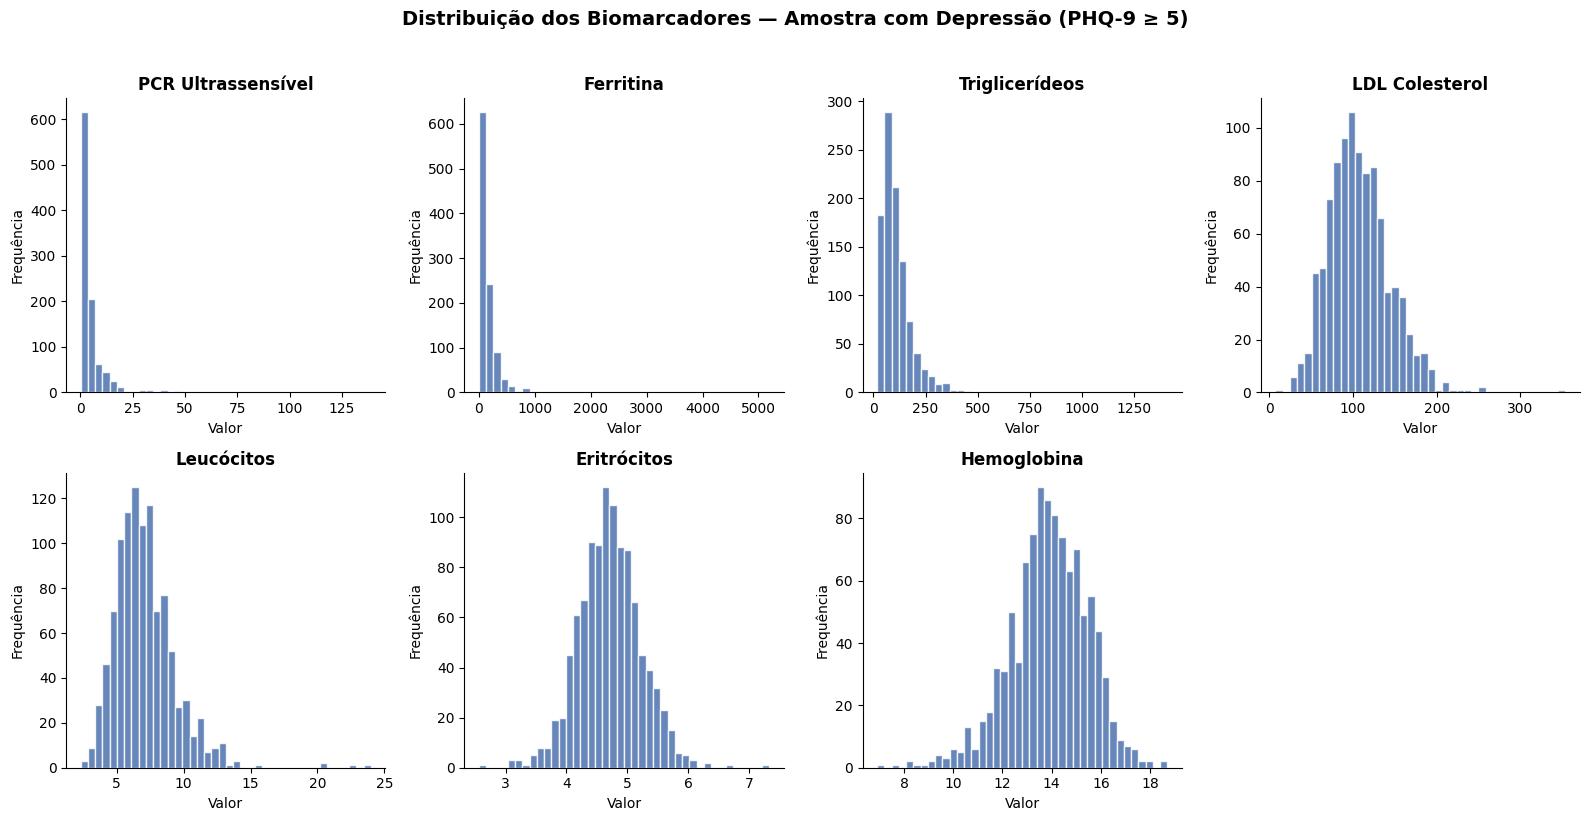

✓ Figura salva: histogramas_biomarcadores.png


In [27]:
os.makedirs('/content/drive/MyDrive/TCC_dados/figuras', exist_ok=True)

cols_bio = ['LBXHSCRP','LBXFER','LBXTR','LBDLDL','LBXWBCSI','LBXRBCSI','LBXHGB']
cols_bio = [c for c in cols_bio if c in df_dep.columns]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cols_bio):
    nome = nomes_legiveis.get(col, col)
    axes[i].hist(df_dep[col].dropna(), bins=40, color='#4C72B0', edgecolor='white', alpha=0.85)
    axes[i].set_title(nome, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Valor', fontsize=10)
    axes[i].set_ylabel('Frequência', fontsize=10)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

# esconder eixo extra
axes[-1].set_visible(False)

plt.suptitle('Distribuição dos Biomarcadores — Amostra com Depressão (PHQ-9 ≥ 5)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/histogramas_biomarcadores.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: histogramas_biomarcadores.png")

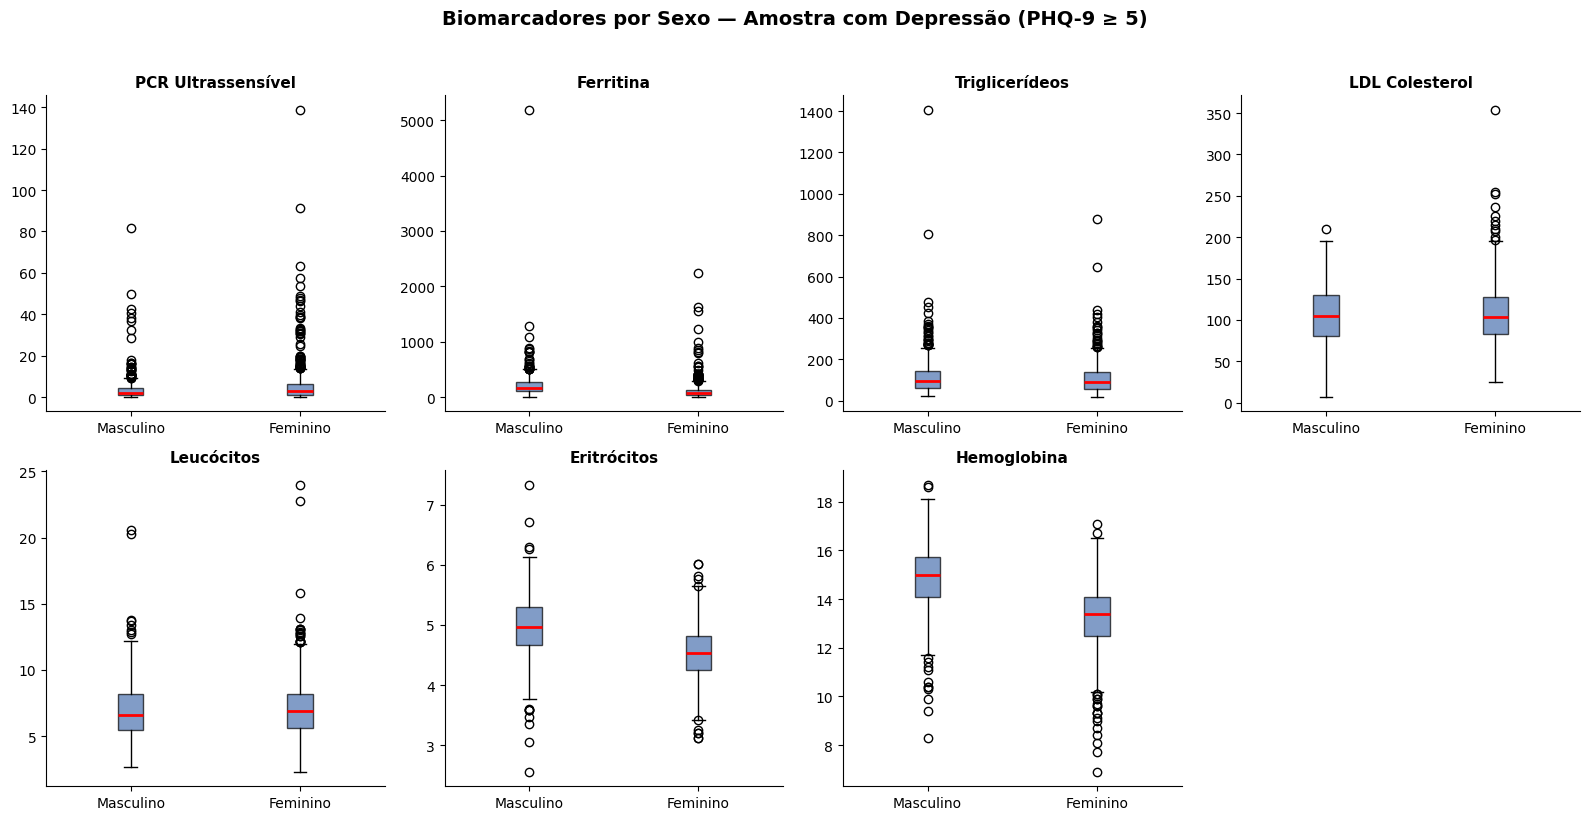

✓ Figura salva: boxplots_sexo.png


In [28]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cols_bio):
    nome = nomes_legiveis.get(col, col)
    data_m = df_dep[df_dep['RIAGENDR'] == 1][col].dropna()
    data_f = df_dep[df_dep['RIAGENDR'] == 2][col].dropna()

    axes[i].boxplot([data_m, data_f],
                    labels=['Masculino', 'Feminino'],
                    patch_artist=True,
                    boxprops=dict(facecolor='#4C72B0', alpha=0.7),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(nome, fontsize=11, fontweight='bold')
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

axes[-1].set_visible(False)
plt.suptitle('Biomarcadores por Sexo — Amostra com Depressão (PHQ-9 ≥ 5)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/boxplots_sexo.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: boxplots_sexo.png")

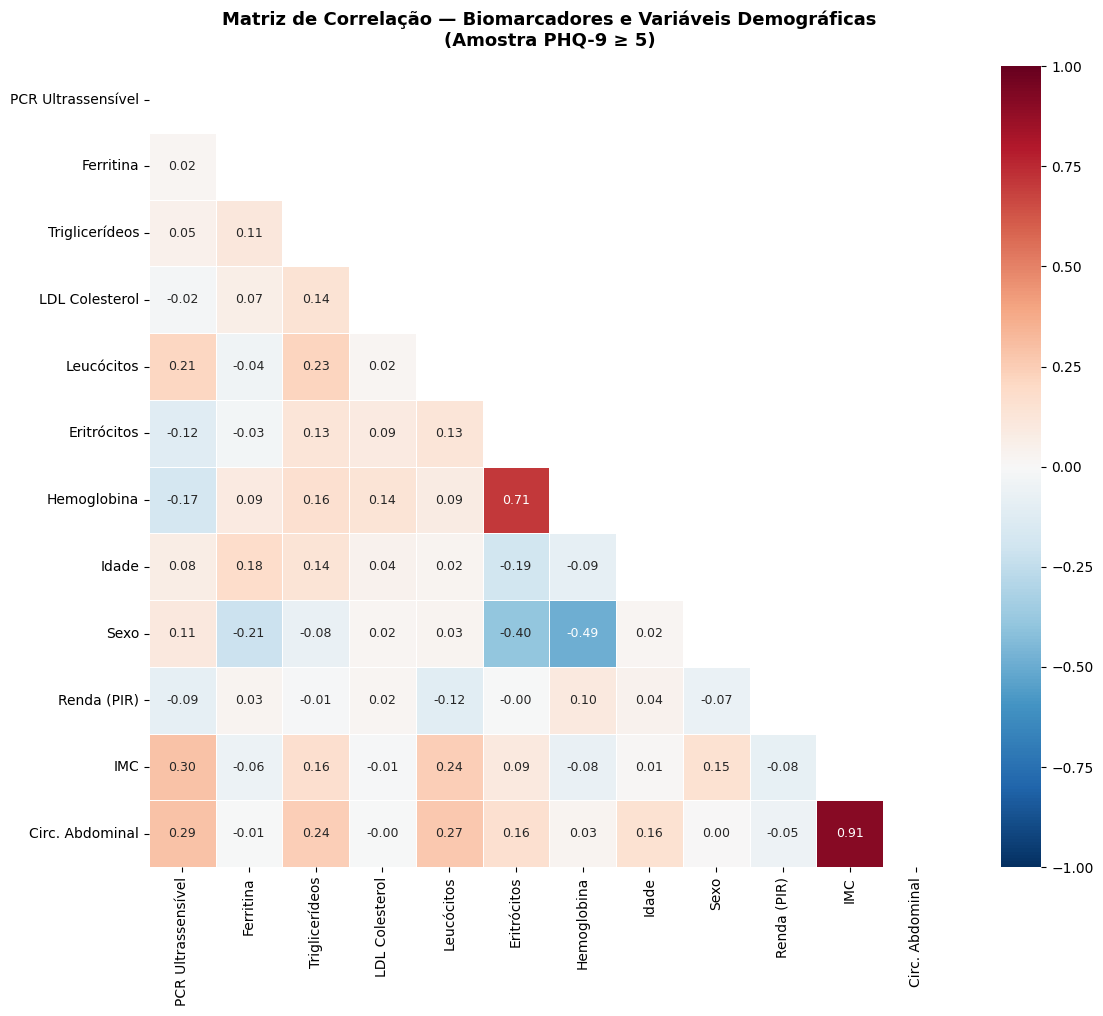

✓ Figura salva: heatmap_correlacao.png


In [29]:
cols_corr = [c for c in colunas_modelo if c in df_dep.columns]
corr = df_dep[cols_corr].corr()

# renomear para nomes legíveis
corr.index   = [nomes_legiveis.get(c, c) for c in corr.index]
corr.columns = [nomes_legiveis.get(c, c) for c in corr.columns]

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr,
            mask=mask,
            annot=True,
            fmt='.2f',
            cmap='RdBu_r',
            center=0,
            vmin=-1, vmax=1,
            square=True,
            linewidths=0.5,
            ax=ax,
            annot_kws={'size': 9})

ax.set_title('Matriz de Correlação — Biomarcadores e Variáveis Demográficas\n(Amostra PHQ-9 ≥ 5)',
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/heatmap_correlacao.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: heatmap_correlacao.png")

✓ Variância explicada:
  PC1: 19.6%
  PC2: 18.4%
  Total: 38.1%


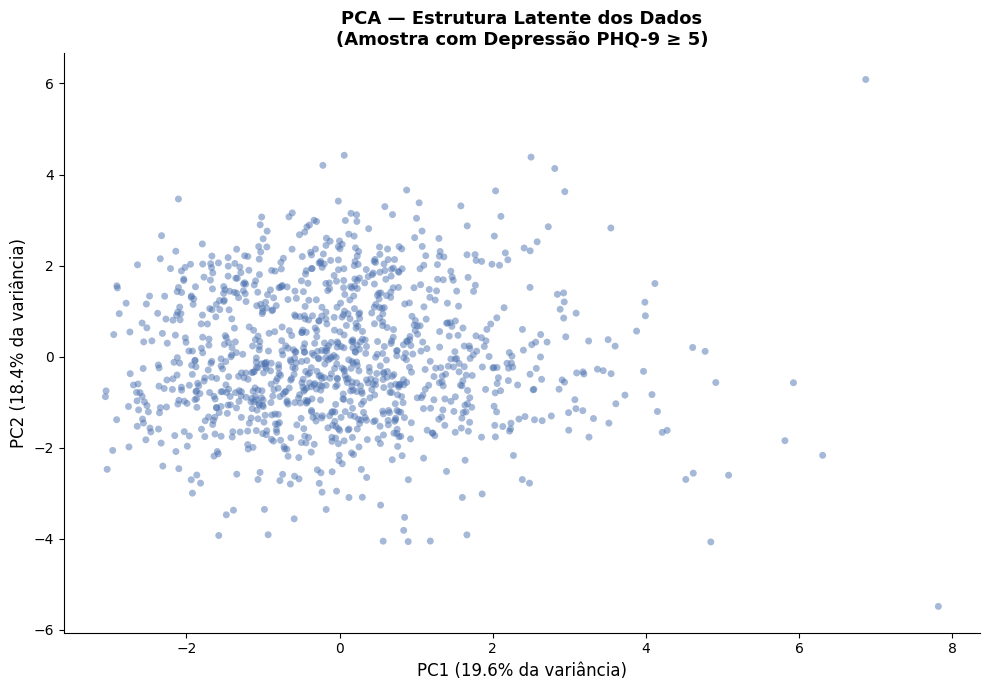

✓ Figura salva: pca_scatter.png
✓ Coordenadas PCA salvas: df_pca.csv


In [30]:
from sklearn.decomposition import PCA

# aplicar PCA com 2 componentes
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(df_scaled)

variancia = pca.explained_variance_ratio_ * 100

print(f"✓ Variância explicada:")
print(f"  PC1: {variancia[0]:.1f}%")
print(f"  PC2: {variancia[1]:.1f}%")
print(f"  Total: {sum(variancia):.1f}%")

# scatter PCA
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(X_pca[:, 0], X_pca[:, 1],
           alpha=0.5, s=25, color='#4C72B0', edgecolors='none')

ax.set_xlabel(f'PC1 ({variancia[0]:.1f}% da variância)', fontsize=12)
ax.set_ylabel(f'PC2 ({variancia[1]:.1f}% da variância)', fontsize=12)
ax.set_title('PCA — Estrutura Latente dos Dados\n(Amostra com Depressão PHQ-9 ≥ 5)',
             fontsize=13, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/pca_scatter.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: pca_scatter.png")

# salvar coordenadas PCA para usar no Dia 4
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca.to_csv('/content/drive/MyDrive/TCC_dados/df_pca.csv', index=False)
print("✓ Coordenadas PCA salvas: df_pca.csv")

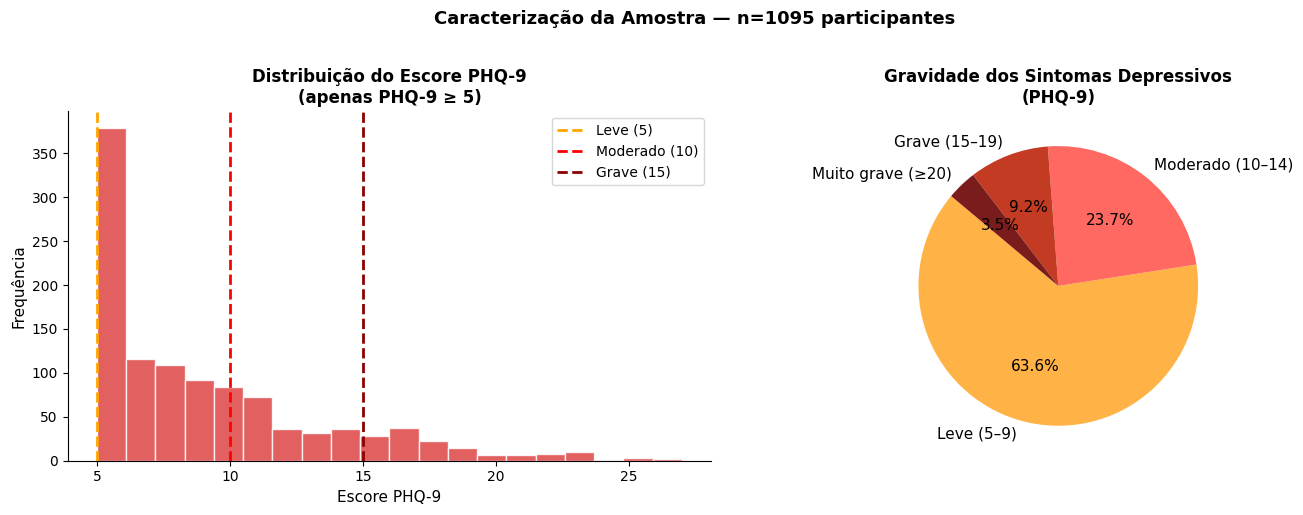

✓ Figura salva: distribuicao_phq9.png


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# histograma do PHQ-9
axes[0].hist(df_dep['PHQ9_total'].dropna(), bins=20,
             color='#DD4444', edgecolor='white', alpha=0.85)
axes[0].axvline(x=5,  color='orange', linestyle='--', linewidth=2, label='Leve (5)')
axes[0].axvline(x=10, color='red',    linestyle='--', linewidth=2, label='Moderado (10)')
axes[0].axvline(x=15, color='darkred',linestyle='--', linewidth=2, label='Grave (15)')
axes[0].set_title('Distribuição do Escore PHQ-9\n(apenas PHQ-9 ≥ 5)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Escore PHQ-9', fontsize=11)
axes[0].set_ylabel('Frequência', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# pizza por nível de gravidade
grupos = {
    'Leve (5–9)':     ((df_dep['PHQ9_total'] >= 5)  & (df_dep['PHQ9_total'] < 10)).sum(),
    'Moderado (10–14)':((df_dep['PHQ9_total'] >= 10) & (df_dep['PHQ9_total'] < 15)).sum(),
    'Grave (15–19)':  ((df_dep['PHQ9_total'] >= 15) & (df_dep['PHQ9_total'] < 20)).sum(),
    'Muito grave (≥20)':( df_dep['PHQ9_total'] >= 20).sum(),
}
cores = ['#FFB347','#FF6961','#C23B22','#7B1C1C']
axes[1].pie(grupos.values(),
            labels=grupos.keys(),
            colors=cores,
            autopct='%1.1f%%',
            startangle=140,
            textprops={'fontsize': 11})
axes[1].set_title('Gravidade dos Sintomas Depressivos\n(PHQ-9)', fontsize=12, fontweight='bold')

plt.suptitle(f'Caracterização da Amostra — n={len(df_dep)} participantes',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/distribuicao_phq9.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: distribuicao_phq9.png")

In [32]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
import os
warnings.filterwarnings('ignore')

pd.reset_option('display.float_format')

# carregar arquivos
df_dep    = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_depressao.csv')
df_scaled = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_scaled.csv')
df_pca    = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_pca.csv')

with open('/content/drive/MyDrive/TCC_dados/colunas_modelo.json') as f:
    colunas_modelo = json.load(f)

os.makedirs('/content/drive/MyDrive/TCC_dados/figuras', exist_ok=True)

print(f"✓ df_dep:    {df_dep.shape[0]} participantes, {df_dep.shape[1]} colunas")
print(f"✓ df_scaled: {df_scaled.shape[0]} participantes, {df_scaled.shape[1]} colunas")
print(f"✓ df_pca:    {df_pca.shape[0]} participantes, {df_pca.shape[1]} colunas")
print(f"✓ Variáveis: {colunas_modelo}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ df_dep:    1095 participantes, 23 colunas
✓ df_scaled: 1095 participantes, 12 colunas
✓ df_pca:    1095 participantes, 2 colunas
✓ Variáveis: ['LBXHSCRP', 'LBXFER', 'LBXTR', 'LBDLDL', 'LBXWBCSI', 'LBXRBCSI', 'LBXHGB', 'RIDAGEYR', 'RIAGENDR', 'INDFMPIR', 'BMXBMI', 'BMXWAIST']


  k=2: inércia = 11455.5
  k=3: inércia = 10231.5
  k=4: inércia = 9663.3
  k=5: inércia = 9142.0
  k=6: inércia = 8692.1
  k=7: inércia = 8264.3
  k=8: inércia = 7787.7
  k=9: inércia = 7441.3
  k=10: inércia = 7185.7


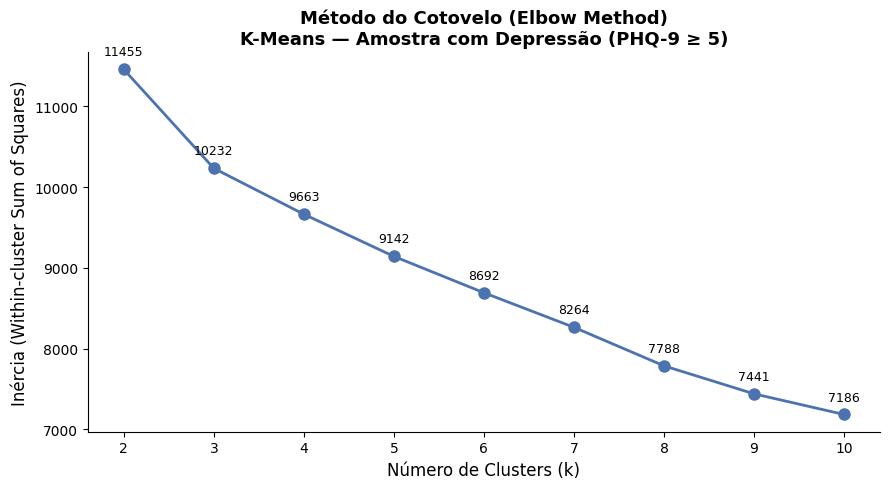

✓ Figura salva: elbow_method.png


In [33]:
  from sklearn.cluster import KMeans

  X = df_scaled.values

  inercias = []
  k_range = range(2, 11)

  for k in k_range:
      km = KMeans(n_clusters=k, random_state=42, n_init=10)
      km.fit(X)
      inercias.append(km.inertia_)
      print(f"  k={k}: inércia = {km.inertia_:.1f}")

  # plotar elbow
  fig, ax = plt.subplots(figsize=(9, 5))
  ax.plot(list(k_range), inercias, 'o-', color='#4C72B0', linewidth=2, markersize=8)
  ax.set_xlabel('Número de Clusters (k)', fontsize=12)
  ax.set_ylabel('Inércia (Within-cluster Sum of Squares)', fontsize=12)
  ax.set_title('Método do Cotovelo (Elbow Method)\nK-Means — Amostra com Depressão (PHQ-9 ≥ 5)',
              fontsize=13, fontweight='bold')
  ax.set_xticks(list(k_range))
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  # marcar ponto de inflexão visualmente
  for i, (k, v) in enumerate(zip(k_range, inercias)):
      ax.annotate(f'{v:.0f}', (k, v), textcoords="offset points",
                  xytext=(0, 10), ha='center', fontsize=9)

  plt.tight_layout()
  plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/elbow_method.png',
              dpi=300, bbox_inches='tight')
  plt.show()
  print("✓ Figura salva: elbow_method.png")

  k=2: Silhouette Score = 0.1456
  k=3: Silhouette Score = 0.1403
  k=4: Silhouette Score = 0.1122
  k=5: Silhouette Score = 0.1217
  k=6: Silhouette Score = 0.1170
  k=7: Silhouette Score = 0.1138
  k=8: Silhouette Score = 0.1192
  k=9: Silhouette Score = 0.1212
  k=10: Silhouette Score = 0.1214

✓ Melhor Silhouette Score: 0.1456 com k=2


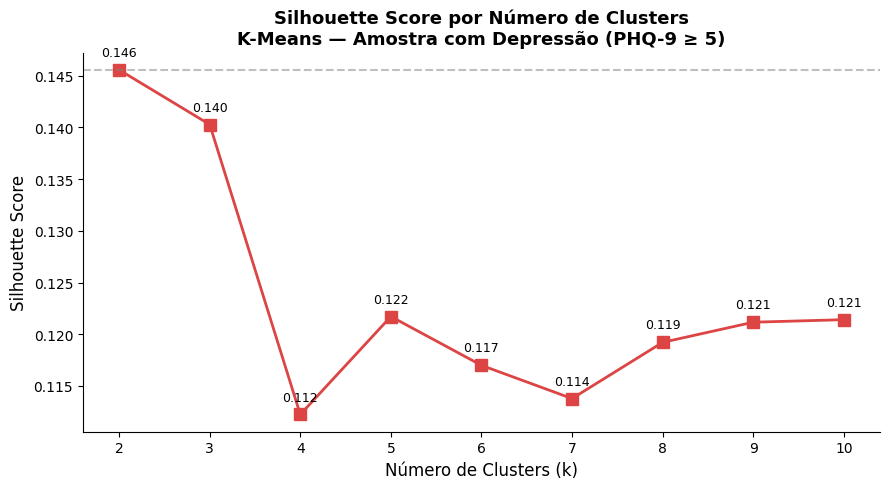

✓ Figura salva: silhouette_scores.png


In [34]:
from sklearn.metrics import silhouette_score

silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouettes.append(score)
    print(f"  k={k}: Silhouette Score = {score:.4f}")

# plotar silhouette
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(list(k_range), silhouettes, 's-', color='#DD4444', linewidth=2, markersize=8)
ax.set_xlabel('Número de Clusters (k)', fontsize=12)
ax.set_ylabel('Silhouette Score', fontsize=12)
ax.set_title('Silhouette Score por Número de Clusters\nK-Means — Amostra com Depressão (PHQ-9 ≥ 5)',
             fontsize=13, fontweight='bold')
ax.set_xticks(list(k_range))
ax.axhline(y=max(silhouettes), color='gray', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for k, s in zip(k_range, silhouettes):
    ax.annotate(f'{s:.3f}', (k, s), textcoords="offset points",
                xytext=(0, 10), ha='center', fontsize=9)

k_ideal = list(k_range)[silhouettes.index(max(silhouettes))]
print(f"\n✓ Melhor Silhouette Score: {max(silhouettes):.4f} com k={k_ideal}")

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/silhouette_scores.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: silhouette_scores.png")

In [35]:
# usar k identificado pelo silhouette
k_final = k_ideal
print(f"✓ Aplicando K-Means com k={k_final}")

km_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
labels_kmeans = km_final.fit_predict(X)

# adicionar labels ao dataframe
df_dep = df_dep.copy()
df_dep['cluster_kmeans'] = labels_kmeans
df_pca['cluster_kmeans'] = labels_kmeans

# contagem por cluster
print("\nDistribuição dos clusters:")
for c in sorted(df_dep['cluster_kmeans'].unique()):
    n = (df_dep['cluster_kmeans'] == c).sum()
    pct = n / len(df_dep) * 100
    print(f"  Cluster {c}: {n} participantes ({pct:.1f}%)")

✓ Aplicando K-Means com k=2

Distribuição dos clusters:
  Cluster 0: 407 participantes (37.2%)
  Cluster 1: 688 participantes (62.8%)


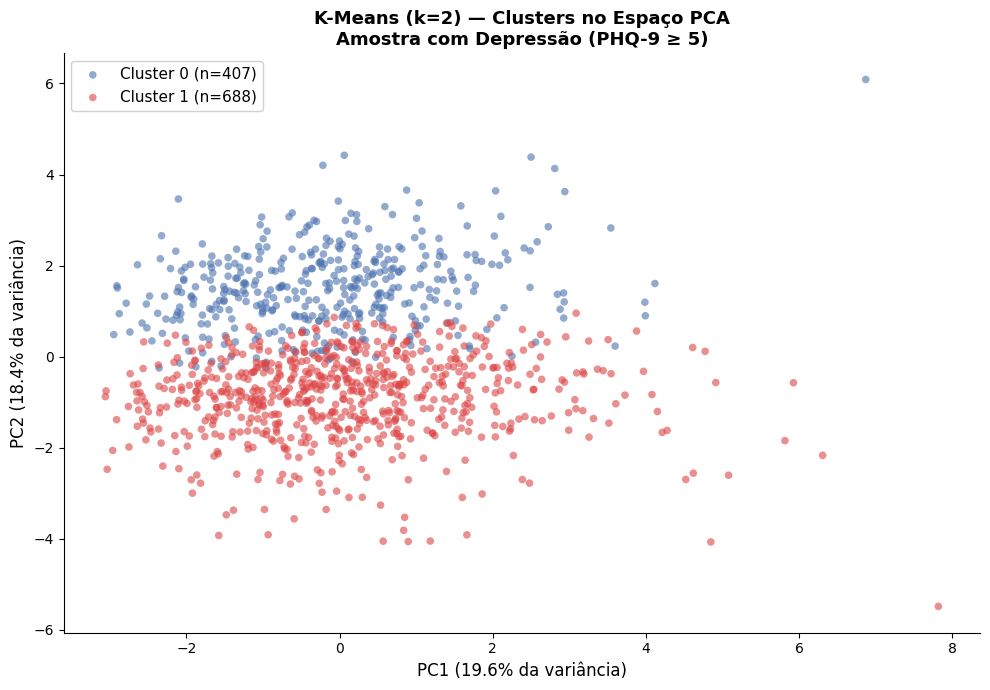

✓ Figura salva: kmeans_pca_scatter.png


In [36]:
cores_cluster = ['#4C72B0','#DD4444','#2CA02C','#FF7F0E','#9467BD']

fig, ax = plt.subplots(figsize=(10, 7))

for c in sorted(df_pca['cluster_kmeans'].unique()):
    mask = df_pca['cluster_kmeans'] == c
    ax.scatter(df_pca.loc[mask, 'PC1'],
               df_pca.loc[mask, 'PC2'],
               label=f'Cluster {c} (n={mask.sum()})',
               alpha=0.6, s=30,
               color=cores_cluster[c],
               edgecolors='none')

ax.set_xlabel(f'PC1 (19.6% da variância)', fontsize=12)
ax.set_ylabel(f'PC2 (18.4% da variância)', fontsize=12)
ax.set_title(f'K-Means (k={k_final}) — Clusters no Espaço PCA\nAmostra com Depressão (PHQ-9 ≥ 5)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/kmeans_pca_scatter.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: kmeans_pca_scatter.png")


=== PERFIL MÉDIO POR CLUSTER ===
cluster_kmeans           0       1
PCR Ultrassensível    3.34    6.33
Ferritina           214.51  120.92
Triglicerídeos      125.71  104.84
LDL Colesterol      109.85  105.83
Leucócitos            7.10    7.04
Eritrócitos           5.07    4.49
Hemoglobina          15.14   13.10
Idade                46.76   50.14
Sexo                  1.05    1.94
Renda (PIR)           2.32    2.06
IMC                  30.08   32.20
Circ. Abdominal     103.56  102.69


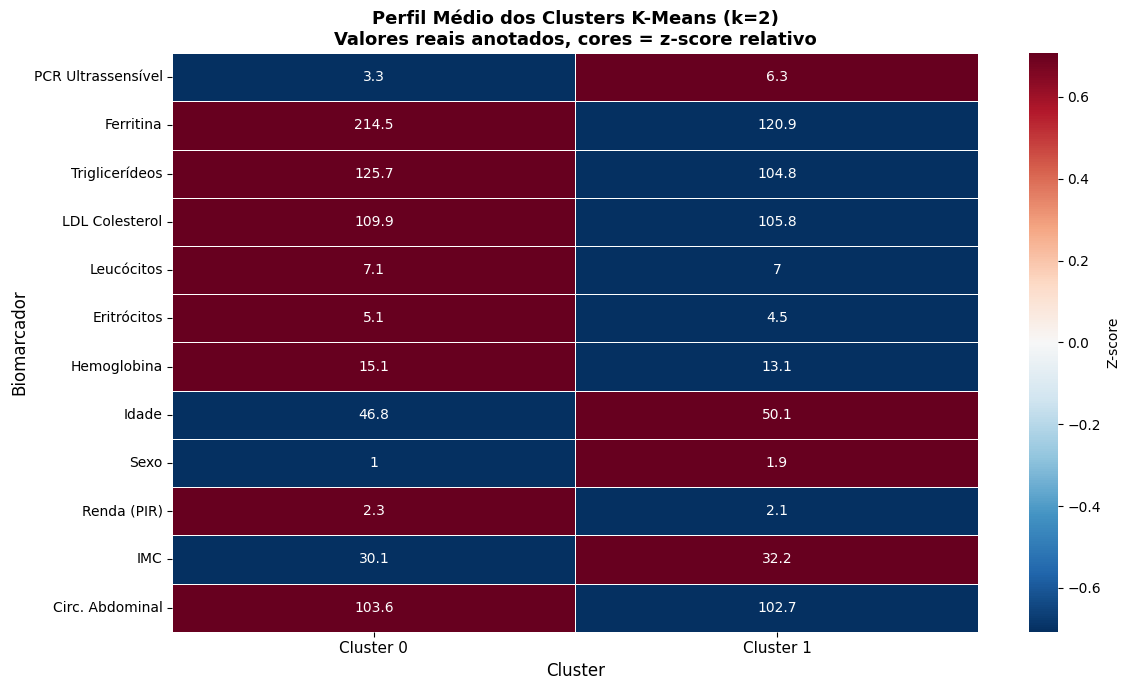

✓ Figura salva: kmeans_perfil_clusters.png


In [37]:
nomes_legiveis = {
    'LBXHSCRP':  'PCR Ultrassensível',
    'LBXFER':    'Ferritina',
    'LBXTR':     'Triglicerídeos',
    'LBDLDL':    'LDL Colesterol',
    'LBXWBCSI':  'Leucócitos',
    'LBXRBCSI':  'Eritrócitos',
    'LBXHGB':    'Hemoglobina',
    'RIDAGEYR':  'Idade',
    'RIAGENDR':  'Sexo',
    'INDFMPIR':  'Renda (PIR)',
    'BMXBMI':    'IMC',
    'BMXWAIST':  'Circ. Abdominal',
}

# média de cada variável por cluster
cols_analise = [c for c in colunas_modelo if c in df_dep.columns]
perfis = df_dep.groupby('cluster_kmeans')[cols_analise].mean()
perfis.columns = [nomes_legiveis.get(c, c) for c in perfis.columns]

print("=== PERFIL MÉDIO POR CLUSTER ===")
print(perfis.T.round(2))

# heatmap dos perfis
fig, ax = plt.subplots(figsize=(12, 7))

# normalizar para visualização (z-score por coluna)
perfis_norm = (perfis - perfis.mean()) / perfis.std()

sns.heatmap(perfis_norm.T,
            annot=perfis.T.round(1),
            fmt='g',
            cmap='RdBu_r',
            center=0,
            linewidths=0.5,
            ax=ax,
            cbar_kws={'label': 'Z-score'},
            annot_kws={'size': 10})

ax.set_title(f'Perfil Médio dos Clusters K-Means (k={k_final})\nValores reais anotados, cores = z-score relativo',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Cluster', fontsize=12)
ax.set_ylabel('Biomarcador', fontsize=12)
ax.set_xticklabels([f'Cluster {i}' for i in range(k_final)], fontsize=11)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/kmeans_perfil_clusters.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: kmeans_perfil_clusters.png")

In [38]:
# salvar df_dep com labels do kmeans
df_dep.to_csv('/content/drive/MyDrive/TCC_dados/df_depressao_clusters.csv', index=False)

# salvar df_pca com labels
df_pca.to_csv('/content/drive/MyDrive/TCC_dados/df_pca.csv', index=False)

# salvar tabela de perfis
perfis.T.round(2).to_csv('/content/drive/MyDrive/TCC_dados/perfis_kmeans.csv')

# salvar silhouette scores para tabela comparativa final
resultados_kmeans = {
    'k_final': int(k_final),
    'silhouette_score': round(max(silhouettes), 4),
    'inercia': round(km_final.inertia_, 2)
}

with open('/content/drive/MyDrive/TCC_dados/resultados_kmeans.json', 'w') as f:
    json.dump(resultados_kmeans, f)

print("✓ Arquivos salvos no Google Drive:")
print("  - df_depressao_clusters.csv  → amostra com labels K-Means")
print("  - df_pca.csv                 → coordenadas PCA com labels")
print("  - perfis_kmeans.csv          → perfil médio por cluster")
print("  - resultados_kmeans.json     → métricas para comparação final")
print(f"\n✓ Resumo K-Means:")
print(f"  k escolhido:       {k_final}")
print(f"  Silhouette Score:  {max(silhouettes):.4f}")
print(f"  Inércia final:     {km_final.inertia_:.1f}")

✓ Arquivos salvos no Google Drive:
  - df_depressao_clusters.csv  → amostra com labels K-Means
  - df_pca.csv                 → coordenadas PCA com labels
  - perfis_kmeans.csv          → perfil médio por cluster
  - resultados_kmeans.json     → métricas para comparação final

✓ Resumo K-Means:
  k escolhido:       2
  Silhouette Score:  0.1456
  Inércia final:     11455.5


In [39]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
import os
warnings.filterwarnings('ignore')
pd.reset_option('display.float_format')

df_dep    = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_depressao_clusters.csv')
df_scaled = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_scaled.csv')
df_pca    = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_pca.csv')

with open('/content/drive/MyDrive/TCC_dados/colunas_modelo.json') as f:
    colunas_modelo = json.load(f)

with open('/content/drive/MyDrive/TCC_dados/resultados_kmeans.json') as f:
    resultados_kmeans = json.load(f)

os.makedirs('/content/drive/MyDrive/TCC_dados/figuras', exist_ok=True)

X = df_scaled.values

print(f"✓ df_dep:    {df_dep.shape[0]} participantes, {df_dep.shape[1]} colunas")
print(f"✓ df_scaled: {df_scaled.shape[0]} participantes, {df_scaled.shape[1]} colunas")
print(f"✓ K-Means anterior: k={resultados_kmeans['k_final']}, Silhouette={resultados_kmeans['silhouette_score']}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ df_dep:    1095 participantes, 24 colunas
✓ df_scaled: 1095 participantes, 12 colunas
✓ K-Means anterior: k=2, Silhouette=0.1456


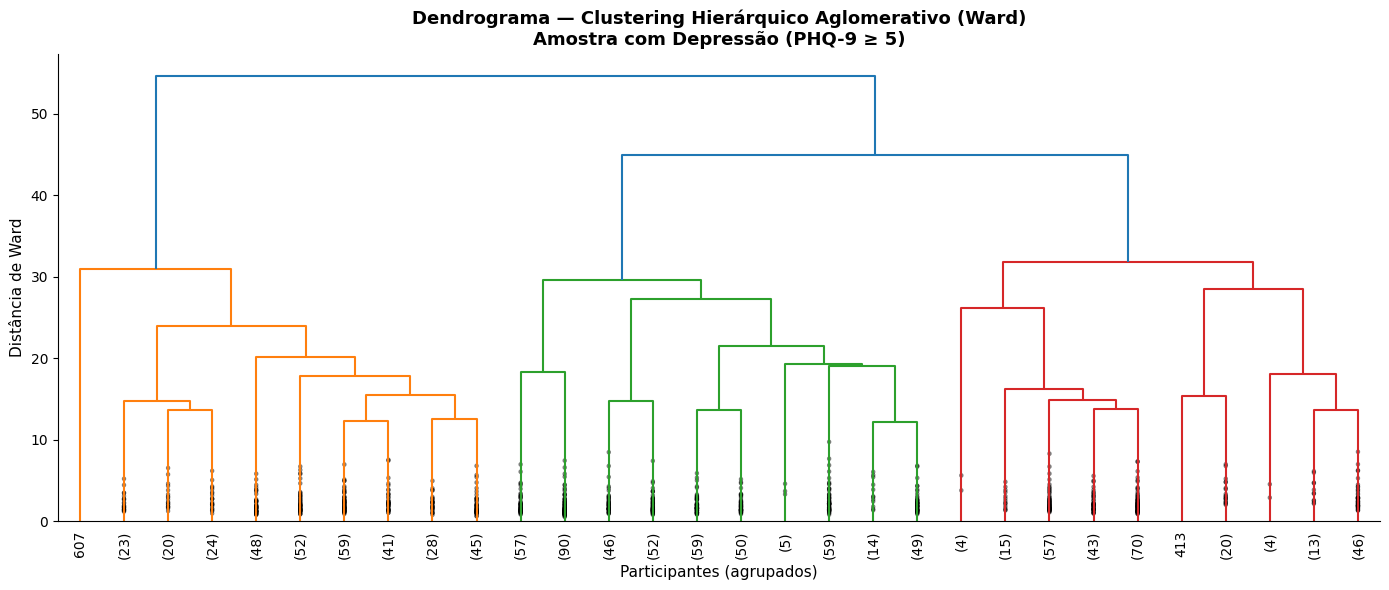

✓ Figura salva: dendrograma.png

Observe a altura dos cortes no dendrograma para identificar o número natural de clusters


In [40]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# calcular linkage com método Ward
# Ward minimiza a variância intra-cluster — melhor para dados contínuos
Z = linkage(X, method='ward')

fig, ax = plt.subplots(figsize=(14, 6))

dendrogram(Z,
           ax=ax,
           truncate_mode='lastp',  # mostra só os últimos p clusters
           p=30,                   # número de folhas visíveis
           leaf_rotation=90,
           leaf_font_size=10,
           show_contracted=True,
           color_threshold=0.7 * max(Z[:, 2]))

ax.set_title('Dendrograma — Clustering Hierárquico Aglomerativo (Ward)\nAmostra com Depressão (PHQ-9 ≥ 5)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Participantes (agrupados)', fontsize=11)
ax.set_ylabel('Distância de Ward', fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/dendrograma.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: dendrograma.png")
print("\nObserve a altura dos cortes no dendrograma para identificar o número natural de clusters")


In [41]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# usar mesmo k do K-Means para comparação direta
k_hier = 2

hier = AgglomerativeClustering(n_clusters=k_hier, linkage='ward')
labels_hier = hier.fit_predict(X)

# adicionar ao dataframe
df_dep['cluster_hier'] = labels_hier
df_pca['cluster_hier'] = labels_hier

# silhouette score
sil_hier = silhouette_score(X, labels_hier)

# comparar com K-Means usando Adjusted Rand Index
ari = adjusted_rand_score(df_dep['cluster_kmeans'], labels_hier)

print(f"✓ Clustering Hierárquico (k={k_hier}, Ward)")
print(f"  Silhouette Score: {sil_hier:.4f}")
print(f"  Adjusted Rand Index vs K-Means: {ari:.4f}")
print(f"\nDistribuição dos clusters:")
for c in sorted(df_dep['cluster_hier'].unique()):
    n = (df_dep['cluster_hier'] == c).sum()
    pct = n / len(df_dep) * 100
    print(f"  Cluster {c}: {n} participantes ({pct:.1f}%)")

✓ Clustering Hierárquico (k=2, Ward)
  Silhouette Score: 0.1303
  Adjusted Rand Index vs K-Means: 0.7201

Distribuição dos clusters:
  Cluster 0: 754 participantes (68.9%)
  Cluster 1: 341 participantes (31.1%)


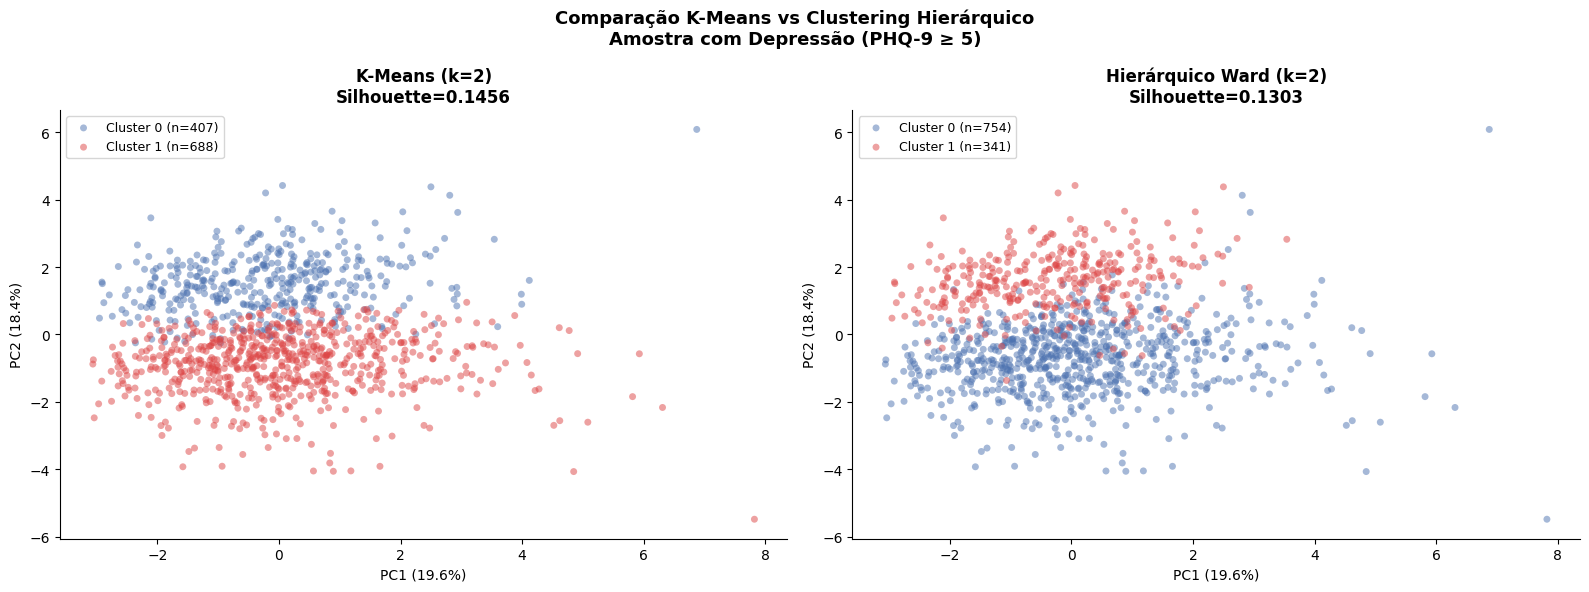

✓ Figura salva: comparacao_kmeans_hier.png


In [42]:
cores_cluster = ['#4C72B0', '#DD4444', '#2CA02C', '#FF7F0E']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means
for c in sorted(df_pca['cluster_kmeans'].unique()):
    mask = df_pca['cluster_kmeans'] == c
    axes[0].scatter(df_pca.loc[mask, 'PC1'],
                    df_pca.loc[mask, 'PC2'],
                    label=f'Cluster {c} (n={mask.sum()})',
                    alpha=0.5, s=25, color=cores_cluster[c], edgecolors='none')
axes[0].set_title(f'K-Means (k=2)\nSilhouette={resultados_kmeans["silhouette_score"]:.4f}',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('PC1 (19.6%)', fontsize=10)
axes[0].set_ylabel('PC2 (18.4%)', fontsize=10)
axes[0].legend(fontsize=9)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Hierárquico
for c in sorted(df_pca['cluster_hier'].unique()):
    mask = df_pca['cluster_hier'] == c
    axes[1].scatter(df_pca.loc[mask, 'PC1'],
                    df_pca.loc[mask, 'PC2'],
                    label=f'Cluster {c} (n={mask.sum()})',
                    alpha=0.5, s=25, color=cores_cluster[c], edgecolors='none')
axes[1].set_title(f'Hierárquico Ward (k=2)\nSilhouette={sil_hier:.4f}',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('PC1 (19.6%)', fontsize=10)
axes[1].set_ylabel('PC2 (18.4%)', fontsize=10)
axes[1].legend(fontsize=9)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Comparação K-Means vs Clustering Hierárquico\nAmostra com Depressão (PHQ-9 ≥ 5)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/comparacao_kmeans_hier.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: comparacao_kmeans_hier.png")

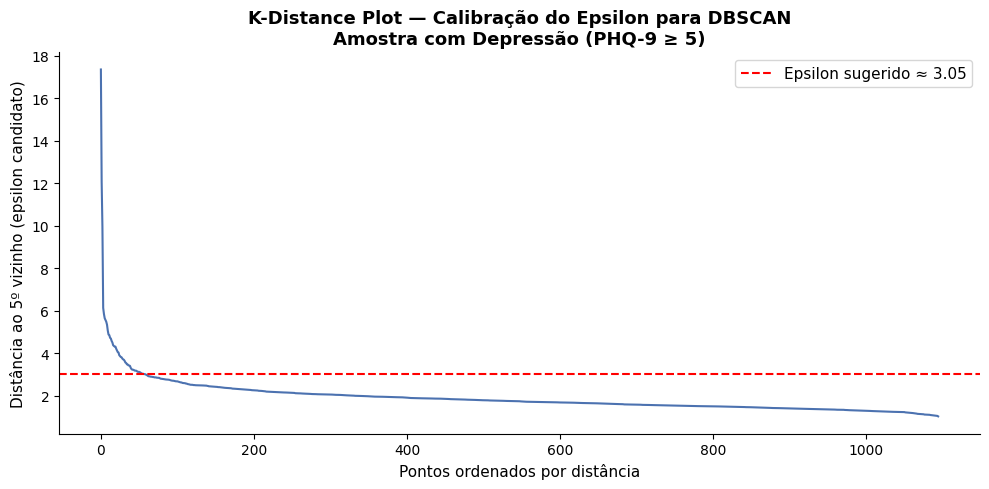

✓ Figura salva: dbscan_kdistance.png
  Epsilon sugerido pelo joelho: 3.046


In [43]:
from sklearn.neighbors import NearestNeighbors

# calcular distância ao 5º vizinho mais próximo para cada ponto
nn = NearestNeighbors(n_neighbors=5)
nn.fit(X)
distancias, _ = nn.kneighbors(X)

# ordenar a distância ao 5º vizinho
dist_5 = np.sort(distancias[:, 4])[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(dist_5, color='#4C72B0', linewidth=1.5)
ax.set_xlabel('Pontos ordenados por distância', fontsize=11)
ax.set_ylabel('Distância ao 5º vizinho (epsilon candidato)', fontsize=11)
ax.set_title('K-Distance Plot — Calibração do Epsilon para DBSCAN\nAmostra com Depressão (PHQ-9 ≥ 5)',
             fontsize=13, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# marcar linha de referência no "joelho" da curva
joelho_idx = int(len(dist_5) * 0.05)
eps_sugerido = dist_5[joelho_idx]
ax.axhline(y=eps_sugerido, color='red', linestyle='--', linewidth=1.5,
           label=f'Epsilon sugerido ≈ {eps_sugerido:.2f}')
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/dbscan_kdistance.png',
            dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Figura salva: dbscan_kdistance.png")
print(f"  Epsilon sugerido pelo joelho: {eps_sugerido:.3f}")

In [44]:
from sklearn.cluster import DBSCAN

eps_valor = eps_sugerido
min_samples = 5

db = DBSCAN(eps=eps_valor, min_samples=min_samples)
labels_dbscan = db.fit_predict(X)

# adicionar ao dataframe
df_dep['cluster_dbscan'] = labels_dbscan
df_pca['cluster_dbscan'] = labels_dbscan

# analisar resultado
n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_outliers  = (labels_dbscan == -1).sum()
n_clustered = (labels_dbscan != -1).sum()

print(f"✓ DBSCAN (eps={eps_valor:.3f}, min_samples={min_samples})")
print(f"  Clusters encontrados: {n_clusters}")
print(f"  Outliers (ruído):     {n_outliers} ({n_outliers/len(labels_dbscan)*100:.1f}%)")
print(f"  Pontos em clusters:   {n_clustered} ({n_clustered/len(labels_dbscan)*100:.1f}%)")

if n_clusters > 1:
    mask_validos = labels_dbscan != -1
    sil_db = silhouette_score(X[mask_validos], labels_dbscan[mask_validos])
    print(f"  Silhouette Score:     {sil_db:.4f}")
else:
    sil_db = None
    print("  Silhouette não calculado (apenas 1 cluster encontrado)")

print(f"\nDistribuição:")
for c in sorted(set(labels_dbscan)):
    n = (labels_dbscan == c).sum()
    label = f'Cluster {c}' if c != -1 else 'Outliers (ruído)'
    print(f"  {label}: {n} ({n/len(labels_dbscan)*100:.1f}%)")

✓ DBSCAN (eps=3.046, min_samples=5)
  Clusters encontrados: 1
  Outliers (ruído):     31 (2.8%)
  Pontos em clusters:   1064 (97.2%)
  Silhouette não calculado (apenas 1 cluster encontrado)

Distribuição:
  Outliers (ruído): 31 (2.8%)
  Cluster 0: 1064 (97.2%)


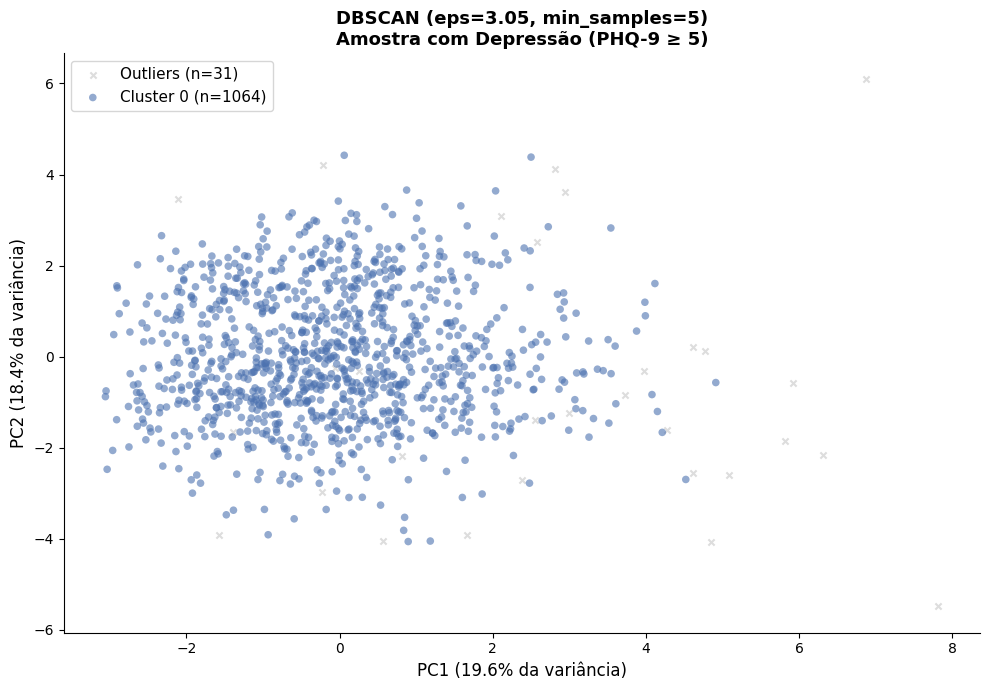

✓ Figura salva: dbscan_scatter.png


In [45]:
fig, ax = plt.subplots(figsize=(10, 7))

clusters_unicos = sorted(set(labels_dbscan))
cores_db = {-1: '#AAAAAA'}
palette = ['#4C72B0','#DD4444','#2CA02C','#FF7F0E','#9467BD']
for i, c in enumerate([x for x in clusters_unicos if x != -1]):
    cores_db[c] = palette[i % len(palette)]

for c in clusters_unicos:
    mask = df_pca['cluster_dbscan'] == c
    label = f'Outliers (n={mask.sum()})' if c == -1 else f'Cluster {c} (n={mask.sum()})'
    marker = 'x' if c == -1 else 'o'
    ax.scatter(df_pca.loc[mask, 'PC1'],
               df_pca.loc[mask, 'PC2'],
               label=label,
               alpha=0.6 if c != -1 else 0.4,
               s=30 if c != -1 else 20,
               color=cores_db[c],
               marker=marker,
               edgecolors='none')

ax.set_xlabel('PC1 (19.6% da variância)', fontsize=12)
ax.set_ylabel('PC2 (18.4% da variância)', fontsize=12)
ax.set_title(f'DBSCAN (eps={eps_valor:.2f}, min_samples={min_samples})\nAmostra com Depressão (PHQ-9 ≥ 5)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/dbscan_scatter.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: dbscan_scatter.png")

In [46]:
tabela = {
    'Algoritmo':         ['K-Means', 'Hierárquico (Ward)', 'DBSCAN'],
    'Nº Clusters':       [resultados_kmeans['k_final'], k_hier, n_clusters],
    'Silhouette Score':  [resultados_kmeans['silhouette_score'],
                          round(sil_hier, 4),
                          round(sil_db, 4) if sil_db else 'N/A'],
    'Outliers':          ['Não detecta', 'Não detecta', f'{n_outliers} ({n_outliers/len(labels_dbscan)*100:.1f}%)'],
    'ARI vs K-Means':    ['—', round(ari, 4), '—'],
}

df_tabela = pd.DataFrame(tabela)
print("=== TABELA COMPARATIVA DOS ALGORITMOS ===")
print(df_tabela.to_string(index=False))

# salvar como CSV para colocar no TCC
df_tabela.to_csv('/content/drive/MyDrive/TCC_dados/tabela_comparativa_algoritmos.csv', index=False)
print("\n✓ Tabela salva: tabela_comparativa_algoritmos.csv")

=== TABELA COMPARATIVA DOS ALGORITMOS ===
         Algoritmo  Nº Clusters Silhouette Score    Outliers ARI vs K-Means
           K-Means            2           0.1456 Não detecta              —
Hierárquico (Ward)            2           0.1303 Não detecta         0.7201
            DBSCAN            1              N/A   31 (2.8%)              —

✓ Tabela salva: tabela_comparativa_algoritmos.csv


In [47]:
# salvar df_dep com todos os labels
df_dep.to_csv('/content/drive/MyDrive/TCC_dados/df_final_todos_clusters.csv', index=False)
df_pca.to_csv('/content/drive/MyDrive/TCC_dados/df_pca_todos_clusters.csv', index=False)

# salvar resultados DBSCAN
resultados_dbscan = {
    'eps': round(float(eps_valor), 4),
    'min_samples': min_samples,
    'n_clusters': n_clusters,
    'n_outliers': int(n_outliers),
    'pct_outliers': round(n_outliers/len(labels_dbscan)*100, 1),
    'silhouette_score': round(sil_db, 4) if sil_db else None
}

with open('/content/drive/MyDrive/TCC_dados/resultados_dbscan.json', 'w') as f:
    json.dump(resultados_dbscan, f)

print("✓ Arquivos salvos no Google Drive:")
print("  - df_final_todos_clusters.csv       → amostra com labels dos 3 algoritmos")
print("  - df_pca_todos_clusters.csv         → PCA com labels dos 3 algoritmos")
print("  - tabela_comparativa_algoritmos.csv → tabela para o TCC")
print("  - resultados_dbscan.json            → métricas do DBSCAN")

✓ Arquivos salvos no Google Drive:
  - df_final_todos_clusters.csv       → amostra com labels dos 3 algoritmos
  - df_pca_todos_clusters.csv         → PCA com labels dos 3 algoritmos
  - tabela_comparativa_algoritmos.csv → tabela para o TCC
  - resultados_dbscan.json            → métricas do DBSCAN


In [48]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
import os
warnings.filterwarnings('ignore')
pd.reset_option('display.float_format')

df_dep = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_final_todos_clusters.csv')
df_pca = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_pca_todos_clusters.csv')
df_scaled = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_scaled.csv')

with open('/content/drive/MyDrive/TCC_dados/colunas_modelo.json') as f:
    colunas_modelo = json.load(f)
with open('/content/drive/MyDrive/TCC_dados/resultados_kmeans.json') as f:
    res_kmeans = json.load(f)
with open('/content/drive/MyDrive/TCC_dados/resultados_dbscan.json') as f:
    res_dbscan = json.load(f)

os.makedirs('/content/drive/MyDrive/TCC_dados/figuras', exist_ok=True)

print(f"✓ df_dep: {df_dep.shape[0]} participantes, {df_dep.shape[1]} colunas")
print(f"✓ Clusters disponíveis: {[c for c in df_dep.columns if 'cluster' in c]}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ df_dep: 1095 participantes, 26 colunas
✓ Clusters disponíveis: ['cluster_kmeans', 'cluster_hier', 'cluster_dbscan']


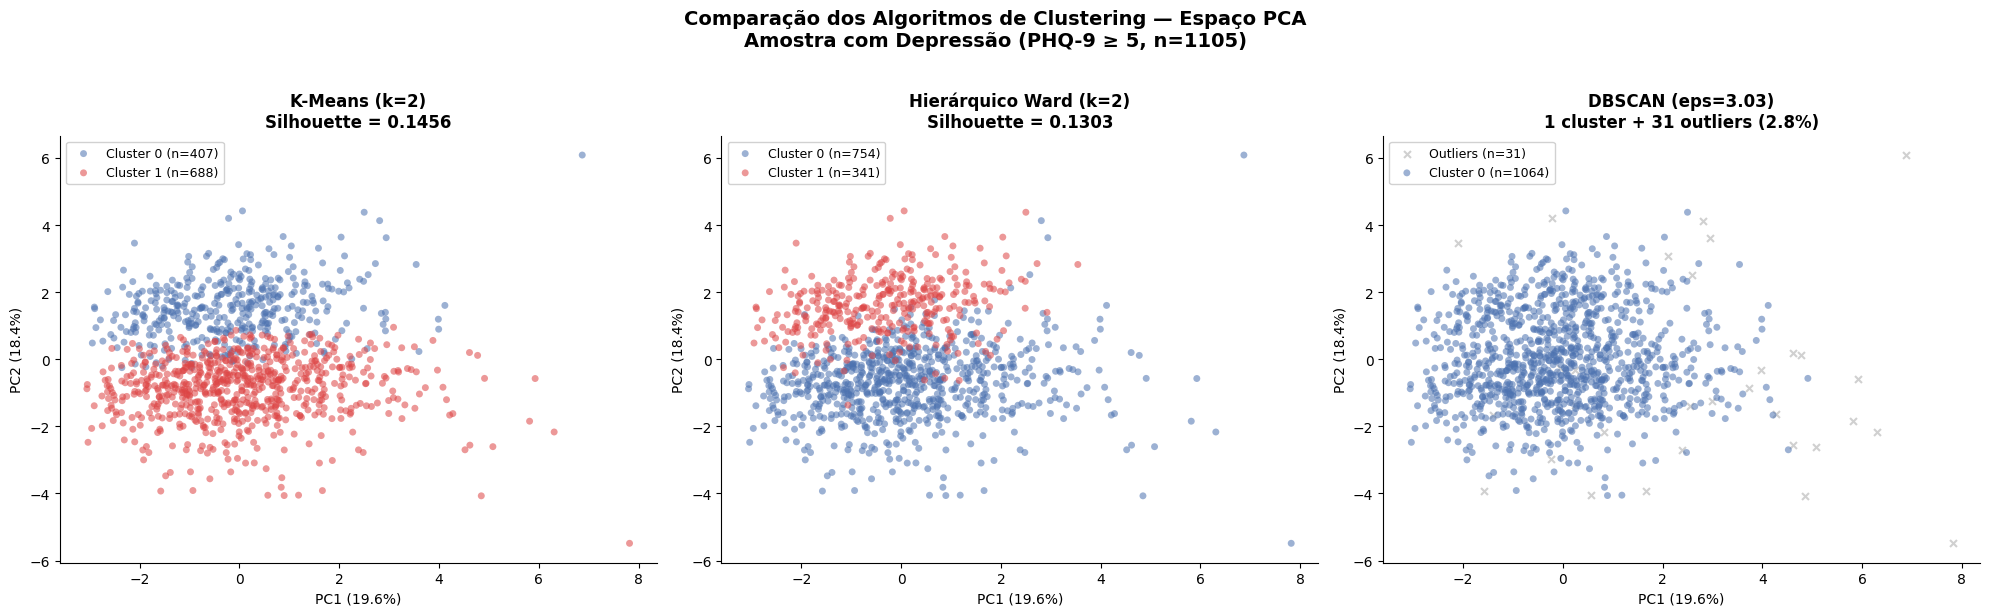

✓ Figura salva: comparacao_3_algoritmos.png


In [49]:
cores = ['#4C72B0','#DD4444','#2CA02C','#FF7F0E']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- K-Means ---
for c in sorted(df_pca['cluster_kmeans'].unique()):
    mask = df_pca['cluster_kmeans'] == c
    axes[0].scatter(df_pca.loc[mask,'PC1'], df_pca.loc[mask,'PC2'],
                    label=f'Cluster {c} (n={mask.sum()})',
                    alpha=0.55, s=25, color=cores[c], edgecolors='none')
axes[0].set_title('K-Means (k=2)\nSilhouette = 0.1456',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('PC1 (19.6%)', fontsize=10)
axes[0].set_ylabel('PC2 (18.4%)', fontsize=10)
axes[0].legend(fontsize=9, framealpha=0.9)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# --- Hierárquico ---
for c in sorted(df_pca['cluster_hier'].unique()):
    mask = df_pca['cluster_hier'] == c
    axes[1].scatter(df_pca.loc[mask,'PC1'], df_pca.loc[mask,'PC2'],
                    label=f'Cluster {c} (n={mask.sum()})',
                    alpha=0.55, s=25, color=cores[c], edgecolors='none')
axes[1].set_title('Hierárquico Ward (k=2)\nSilhouette = 0.1303',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('PC1 (19.6%)', fontsize=10)
axes[1].set_ylabel('PC2 (18.4%)', fontsize=10)
axes[1].legend(fontsize=9, framealpha=0.9)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# --- DBSCAN ---
for c in sorted(df_pca['cluster_dbscan'].unique()):
    mask = df_pca['cluster_dbscan'] == c
    label = f'Outliers (n={mask.sum()})' if c == -1 else f'Cluster {c} (n={mask.sum()})'
    cor = '#AAAAAA' if c == -1 else cores[c]
    marker = 'x' if c == -1 else 'o'
    axes[2].scatter(df_pca.loc[mask,'PC1'], df_pca.loc[mask,'PC2'],
                    label=label, alpha=0.55, s=25,
                    color=cor, marker=marker, edgecolors='none')
axes[2].set_title(f'DBSCAN (eps=3.03)\n1 cluster + 31 outliers (2.8%)',
                  fontsize=12, fontweight='bold')
axes[2].set_xlabel('PC1 (19.6%)', fontsize=10)
axes[2].set_ylabel('PC2 (18.4%)', fontsize=10)
axes[2].legend(fontsize=9, framealpha=0.9)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

plt.suptitle('Comparação dos Algoritmos de Clustering — Espaço PCA\nAmostra com Depressão (PHQ-9 ≥ 5, n=1105)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/comparacao_3_algoritmos.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: comparacao_3_algoritmos.png")

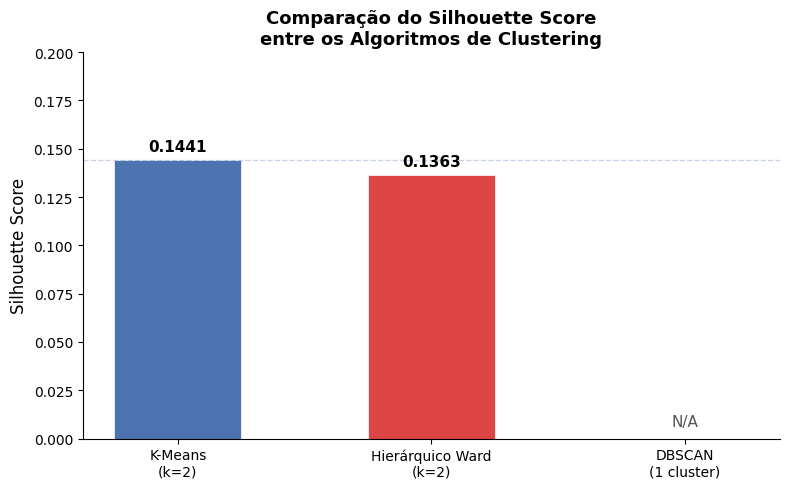

✓ Figura salva: comparacao_silhouette.png


In [50]:
fig, ax = plt.subplots(figsize=(8, 5))

algoritmos = ['K-Means\n(k=2)', 'Hierárquico Ward\n(k=2)', 'DBSCAN\n(1 cluster)']
scores     = [0.1441, 0.1363, 0]
cores_bar  = ['#4C72B0', '#DD4444', '#AAAAAA']

bars = ax.bar(algoritmos, scores, color=cores_bar,
              edgecolor='white', linewidth=0.5, width=0.5)

for bar, score in zip(bars, scores):
    if score > 0:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.003,
                f'{score:.4f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')
    else:
        ax.text(bar.get_x() + bar.get_width()/2,
                0.005, 'N/A',
                ha='center', va='bottom', fontsize=11, color='#555555')

ax.set_ylabel('Silhouette Score', fontsize=12)
ax.set_title('Comparação do Silhouette Score\nentre os Algoritmos de Clustering',
             fontsize=13, fontweight='bold')
ax.set_ylim(0, 0.20)
ax.axhline(y=0.1441, color='#4C72B0', linestyle='--', alpha=0.3, linewidth=1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/comparacao_silhouette.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: comparacao_silhouette.png")

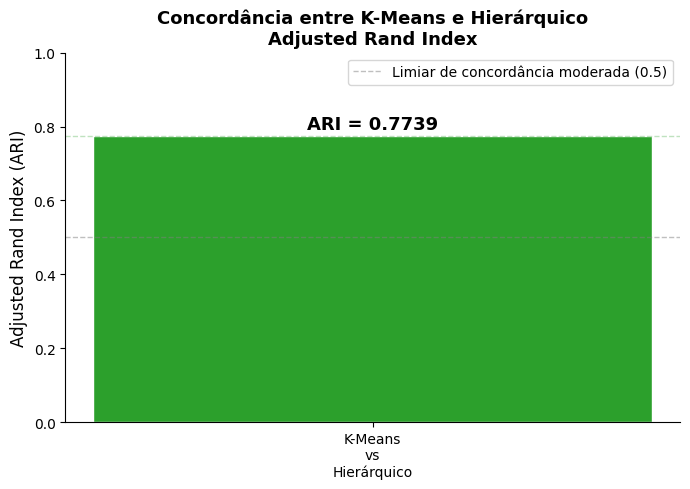

✓ Figura salva: ari_concordancia.png


In [51]:
fig, ax = plt.subplots(figsize=(7, 5))

labels_ari = ['K-Means\nvs\nHierárquico']
valores_ari = [0.7739]

bars = ax.bar(labels_ari, valores_ari,
              color='#2CA02C', edgecolor='white', width=0.3)

ax.text(bars[0].get_x() + bars[0].get_width()/2,
        valores_ari[0] + 0.01,
        f'ARI = {valores_ari[0]:.4f}',
        ha='center', va='bottom', fontsize=13, fontweight='bold')

ax.set_ylabel('Adjusted Rand Index (ARI)', fontsize=12)
ax.set_title('Concordância entre K-Means e Hierárquico\nAdjusted Rand Index',
             fontsize=13, fontweight='bold')
ax.set_ylim(0, 1.0)
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5,
           linewidth=1, label='Limiar de concordância moderada (0.5)')
ax.axhline(y=0.7739, color='#2CA02C', linestyle='--', alpha=0.3, linewidth=1)
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/ari_concordancia.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: ari_concordancia.png")

In [52]:
pasta_figuras = '/content/drive/MyDrive/TCC_dados/figuras/'
figuras = sorted(os.listdir(pasta_figuras))

print(f"✓ Total de figuras salvas: {len(figuras)}")
print()
for f in figuras:
    tamanho = os.path.getsize(pasta_figuras + f) / 1024
    print(f"  {f} ({tamanho:.0f} KB)")

✓ Total de figuras salvas: 20

  ari_concordancia.png (113 KB)
  barplots_biomarcadores_cluster.png (302 KB)
  barplots_demograficos_cluster.png (201 KB)
  boxplots_sexo.png (345 KB)
  comparacao_3_algoritmos.png (990 KB)
  comparacao_kmeans_hier.png (917 KB)
  comparacao_silhouette.png (126 KB)
  dbscan_kdistance.png (163 KB)
  dbscan_scatter.png (580 KB)
  dendrograma.png (216 KB)
  distribuicao_phq9.png (239 KB)
  elbow_method.png (189 KB)
  heatmap_correlacao.png (389 KB)
  histogramas_biomarcadores.png (280 KB)
  kmeans_pca_scatter.png (581 KB)
  kmeans_perfil_clusters.png (231 KB)
  pca_scatter.png (524 KB)
  phq9_por_cluster.png (166 KB)
  sexo_por_cluster.png (165 KB)
  silhouette_scores.png (178 KB)


In [53]:
pasta_figuras = '/content/drive/MyDrive/TCC_dados/figuras/'
figuras = sorted(os.listdir(pasta_figuras))

print(f"✓ Total de figuras salvas: {len(figuras)}")
print()
for f in figuras:
    tamanho = os.path.getsize(pasta_figuras + f) / 1024
    print(f"  {f} ({tamanho:.0f} KB)")

✓ Total de figuras salvas: 20

  ari_concordancia.png (113 KB)
  barplots_biomarcadores_cluster.png (302 KB)
  barplots_demograficos_cluster.png (201 KB)
  boxplots_sexo.png (345 KB)
  comparacao_3_algoritmos.png (990 KB)
  comparacao_kmeans_hier.png (917 KB)
  comparacao_silhouette.png (126 KB)
  dbscan_kdistance.png (163 KB)
  dbscan_scatter.png (580 KB)
  dendrograma.png (216 KB)
  distribuicao_phq9.png (239 KB)
  elbow_method.png (189 KB)
  heatmap_correlacao.png (389 KB)
  histogramas_biomarcadores.png (280 KB)
  kmeans_pca_scatter.png (581 KB)
  kmeans_perfil_clusters.png (231 KB)
  pca_scatter.png (524 KB)
  phq9_por_cluster.png (166 KB)
  sexo_por_cluster.png (165 KB)
  silhouette_scores.png (178 KB)


In [54]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
import os
warnings.filterwarnings('ignore')
pd.reset_option('display.float_format')

df_dep = pd.read_csv('/content/drive/MyDrive/TCC_dados/df_final_todos_clusters.csv')

with open('/content/drive/MyDrive/TCC_dados/colunas_modelo.json') as f:
    colunas_modelo = json.load(f)

os.makedirs('/content/drive/MyDrive/TCC_dados/figuras', exist_ok=True)

nomes_legiveis = {
    'LBXHSCRP':  'PCR Ultrassensível',
    'LBXFER':    'Ferritina',
    'LBXTR':     'Triglicerídeos',
    'LBDLDL':    'LDL Colesterol',
    'LBXWBCSI':  'Leucócitos',
    'LBXRBCSI':  'Eritrócitos',
    'LBXHGB':    'Hemoglobina',
    'RIDAGEYR':  'Idade',
    'RIAGENDR':  'Sexo',
    'INDFMPIR':  'Renda (PIR)',
    'BMXBMI':    'IMC',
    'BMXWAIST':  'Circ. Abdominal',
}

nomes_clusters = {
    0: 'Cluster 0\n(Imuno-inflamatório)',
    1: 'Cluster 1\n(Hematológico-Metabólico)'
}

print(f"✓ df_dep: {df_dep.shape[0]} participantes, {df_dep.shape[1]} colunas")
print(f"✓ Distribuição K-Means:")
for c in sorted(df_dep['cluster_kmeans'].unique()):
    n = (df_dep['cluster_kmeans'] == c).sum()
    print(f"  Cluster {c}: {n} participantes ({n/len(df_dep)*100:.1f}%)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ df_dep: 1095 participantes, 26 colunas
✓ Distribuição K-Means:
  Cluster 0: 407 participantes (37.2%)
  Cluster 1: 688 participantes (62.8%)


In [55]:
cols_analise = [c for c in colunas_modelo if c in df_dep.columns]

perfis = df_dep.groupby('cluster_kmeans')[cols_analise].mean()
perfis.columns = [nomes_legiveis.get(c, c) for c in perfis.columns]
perfis.index = [f'Cluster {i}' for i in perfis.index]

print("=== PERFIL MÉDIO POR CLUSTER (K-Means) ===")
print(perfis.T.round(2).to_string())

# salvar tabela
perfis.T.round(2).to_csv('/content/drive/MyDrive/TCC_dados/tabela_perfil_clusters.csv')
print("\n✓ Tabela salva: tabela_perfil_clusters.csv")

=== PERFIL MÉDIO POR CLUSTER (K-Means) ===
                    Cluster 0  Cluster 1
PCR Ultrassensível       3.34       6.33
Ferritina              214.51     120.92
Triglicerídeos         125.71     104.84
LDL Colesterol         109.85     105.83
Leucócitos               7.10       7.04
Eritrócitos              5.07       4.49
Hemoglobina             15.14      13.10
Idade                   46.76      50.14
Sexo                     1.05       1.94
Renda (PIR)              2.32       2.06
IMC                     30.08      32.20
Circ. Abdominal        103.56     102.69

✓ Tabela salva: tabela_perfil_clusters.csv


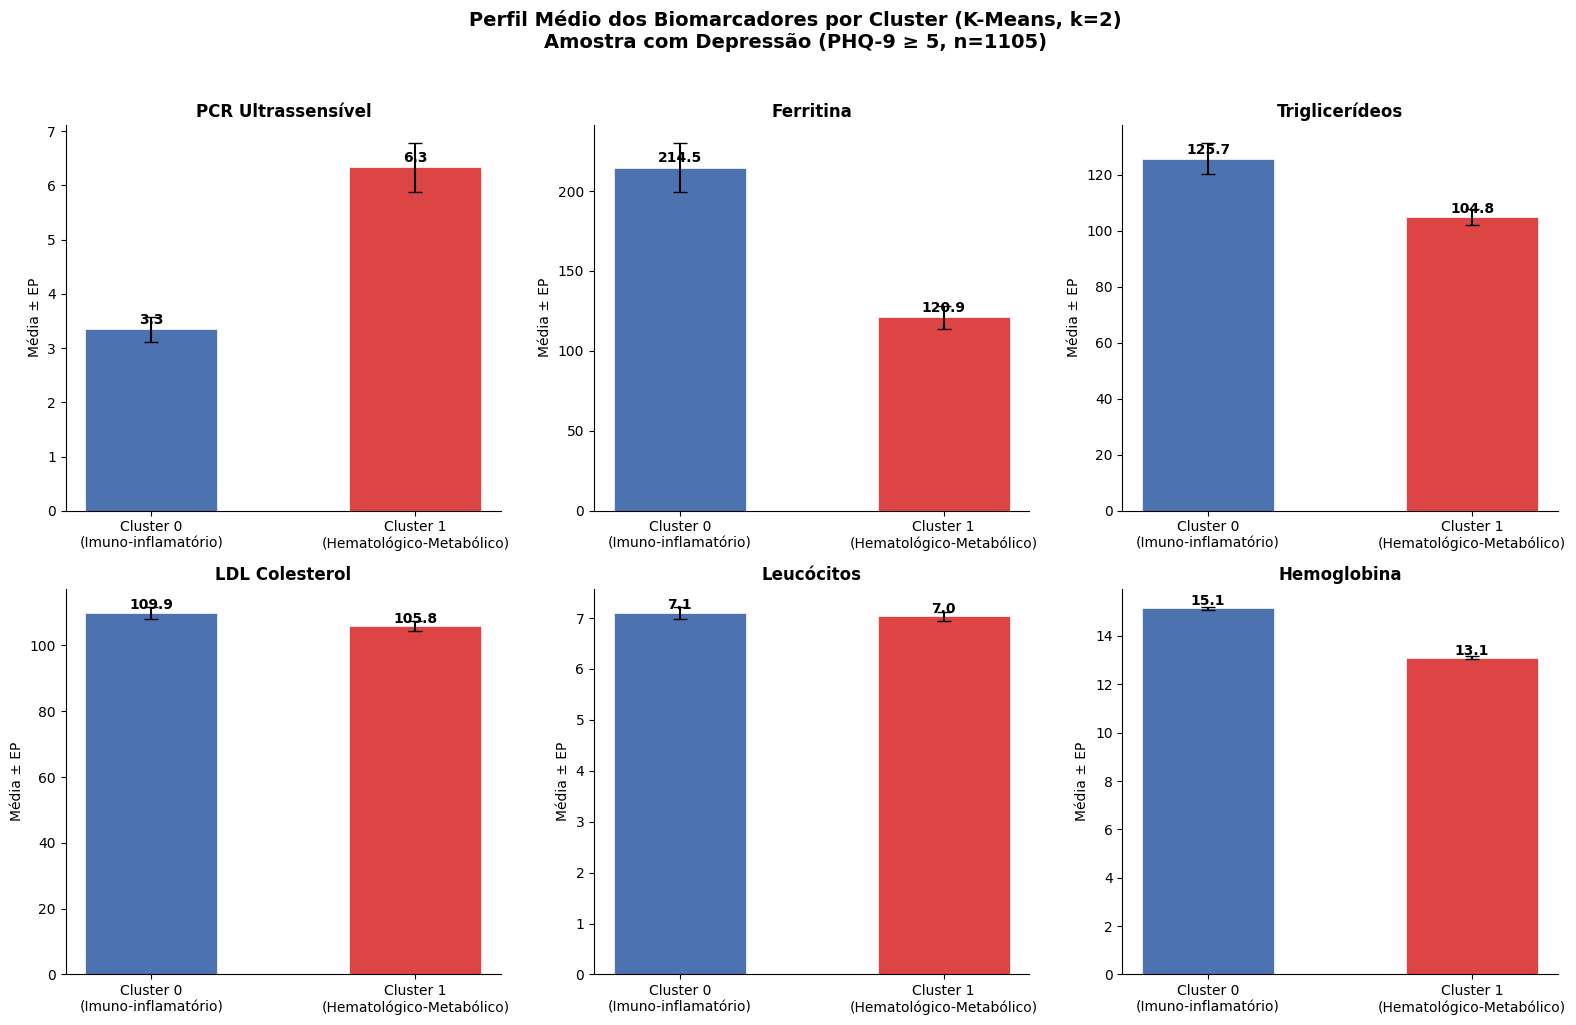

✓ Figura salva: barplots_biomarcadores_cluster.png


In [56]:
cols_bio = ['LBXHSCRP','LBXFER','LBXTR','LBDLDL','LBXWBCSI','LBXHGB']
cols_bio = [c for c in cols_bio if c in df_dep.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

cores_cluster = ['#4C72B0', '#DD4444']

for i, col in enumerate(cols_bio):
    nome = nomes_legiveis.get(col, col)
    medias = df_dep.groupby('cluster_kmeans')[col].mean()
    erros  = df_dep.groupby('cluster_kmeans')[col].sem()

    bars = axes[i].bar(
        [nomes_clusters[0], nomes_clusters[1]],
        medias.values,
        yerr=erros.values,
        color=cores_cluster,
        edgecolor='white',
        linewidth=0.5,
        capsize=5,
        width=0.5
    )

    for bar, val in zip(bars, medias.values):
        axes[i].text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + erros.values.max() * 0.1,
            f'{val:.1f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold'
        )

    axes[i].set_title(nome, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Média ± EP', fontsize=10)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

plt.suptitle('Perfil Médio dos Biomarcadores por Cluster (K-Means, k=2)\nAmostra com Depressão (PHQ-9 ≥ 5, n=1105)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/barplots_biomarcadores_cluster.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: barplots_biomarcadores_cluster.png")

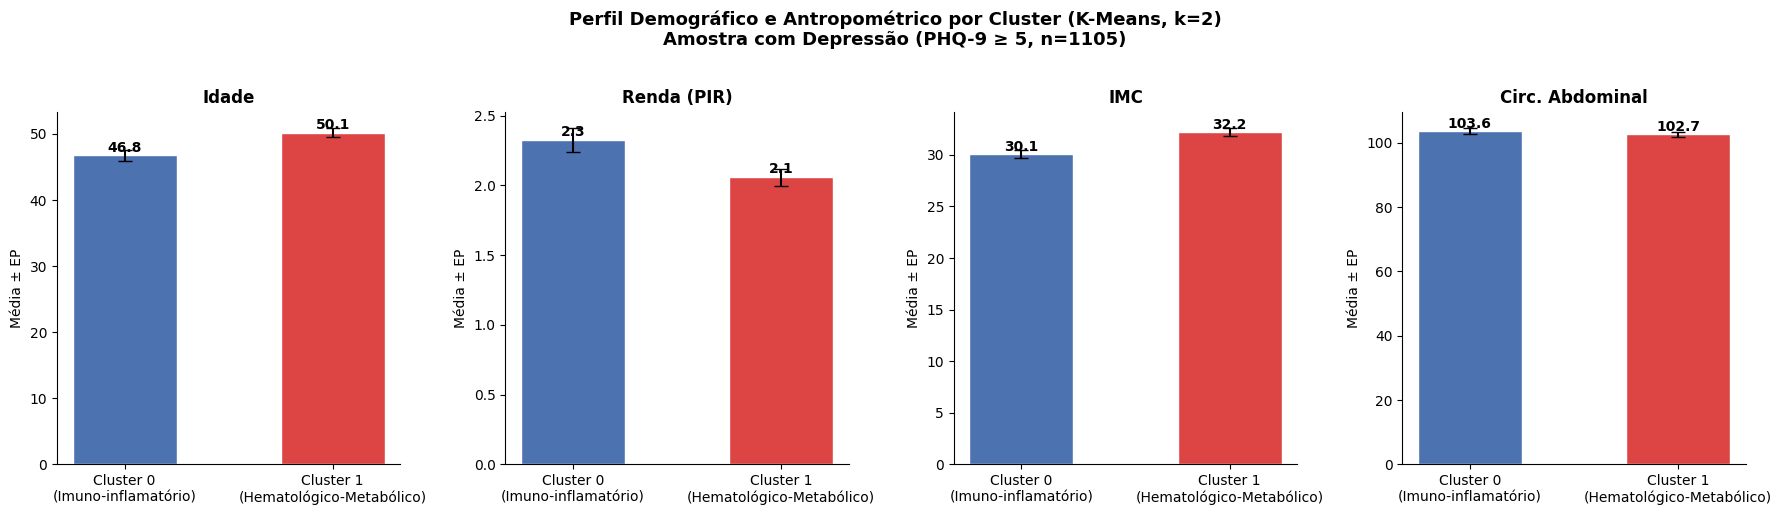

✓ Figura salva: barplots_demograficos_cluster.png


In [57]:
cols_demo = ['RIDAGEYR','INDFMPIR','BMXBMI','BMXWAIST']
cols_demo = [c for c in cols_demo if c in df_dep.columns]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(cols_demo):
    nome = nomes_legiveis.get(col, col)
    medias = df_dep.groupby('cluster_kmeans')[col].mean()
    erros  = df_dep.groupby('cluster_kmeans')[col].sem()

    bars = axes[i].bar(
        [nomes_clusters[0], nomes_clusters[1]],
        medias.values,
        yerr=erros.values,
        color=cores_cluster,
        edgecolor='white',
        capsize=5,
        width=0.5
    )

    for bar, val in zip(bars, medias.values):
        axes[i].text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + erros.values.max() * 0.1,
            f'{val:.1f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold'
        )

    axes[i].set_title(nome, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Média ± EP', fontsize=10)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)

plt.suptitle('Perfil Demográfico e Antropométrico por Cluster (K-Means, k=2)\nAmostra com Depressão (PHQ-9 ≥ 5, n=1105)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/barplots_demograficos_cluster.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: barplots_demograficos_cluster.png")

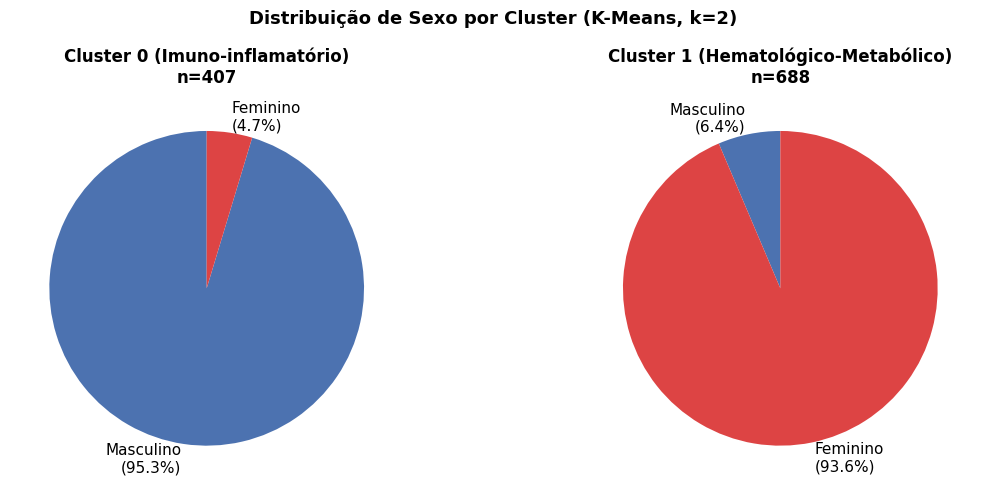

✓ Figura salva: sexo_por_cluster.png


In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for c in [0, 1]:
    dados = df_dep[df_dep['cluster_kmeans'] == c]
    sexo_counts = dados['RIAGENDR'].value_counts()
    total = sexo_counts.sum()
    labels = ['Masculino', 'Feminino']
    valores = [sexo_counts.get(1, 0), sexo_counts.get(2, 0)]
    pcts = [v/total*100 for v in valores]

    axes[c].pie(valores,
                labels=[f'{l}\n({p:.1f}%)' for l, p in zip(labels, pcts)],
                colors=['#4C72B0','#DD4444'],
                autopct='',
                startangle=90,
                textprops={'fontsize': 11})
    axes[c].set_title(f'{nomes_clusters[c].replace(chr(10), " ")}\nn={len(dados)}',
                      fontsize=12, fontweight='bold')

plt.suptitle('Distribuição de Sexo por Cluster (K-Means, k=2)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/sexo_por_cluster.png',
            dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figura salva: sexo_por_cluster.png")

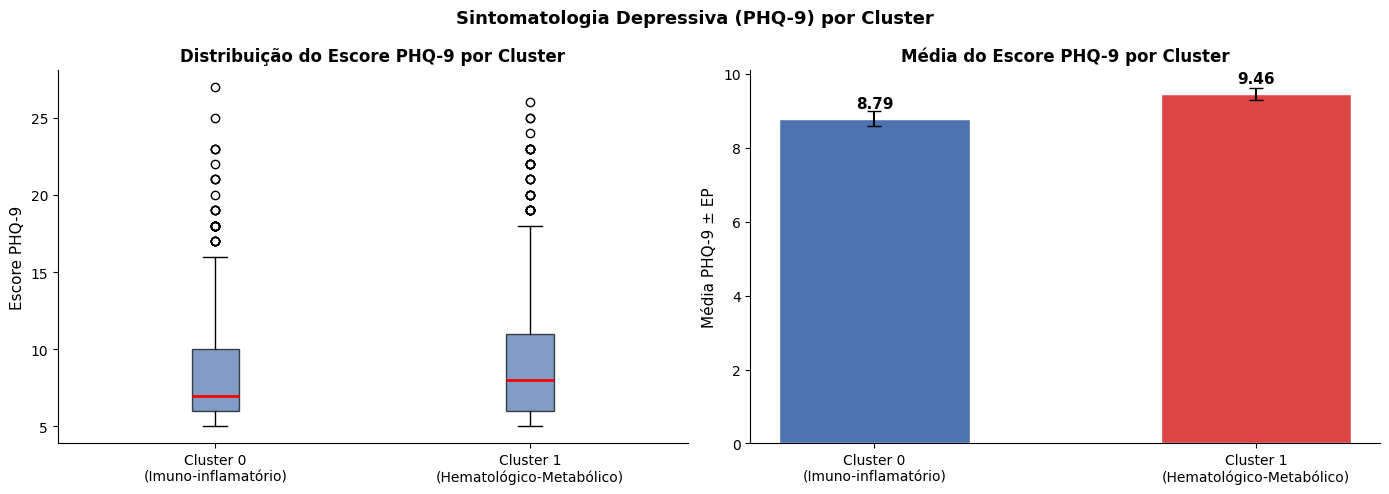

✓ Figura salva: phq9_por_cluster.png

Média PHQ-9 Cluster 0: 8.79
Média PHQ-9 Cluster 1: 9.46


In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# boxplot PHQ-9 por cluster
dados_0 = df_dep[df_dep['cluster_kmeans'] == 0]['PHQ9_total'].dropna()
dados_1 = df_dep[df_dep['cluster_kmeans'] == 1]['PHQ9_total'].dropna()

axes[0].boxplot([dados_0, dados_1],
                labels=['Cluster 0\n(Imuno-inflamatório)',
                        'Cluster 1\n(Hematológico-Metabólico)'],
                patch_artist=True,
                boxprops=dict(facecolor='#4C72B0', alpha=0.7),
                medianprops=dict(color='red', linewidth=2))
axes[0].set_title('Distribuição do Escore PHQ-9 por Cluster',
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel('Escore PHQ-9', fontsize=11)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# média PHQ-9 por cluster
medias_phq9 = df_dep.groupby('cluster_kmeans')['PHQ9_total'].mean()
erros_phq9  = df_dep.groupby('cluster_kmeans')['PHQ9_total'].sem()

bars = axes[1].bar(
    ['Cluster 0\n(Imuno-inflamatório)', 'Cluster 1\n(Hematológico-Metabólico)'],
    medias_phq9.values,
    yerr=erros_phq9.values,
    color=cores_cluster, capsize=5, width=0.5,
    edgecolor='white'
)

for bar, val in zip(bars, medias_phq9.values):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.2,
                 f'{val:.2f}', ha='center', va='bottom',
                 fontsize=11, fontweight='bold')

axes[1].set_title('Média do Escore PHQ-9 por Cluster',
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel('Média PHQ-9 ± EP', fontsize=11)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Sintomatologia Depressiva (PHQ-9) por Cluster',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TCC_dados/figuras/phq9_por_cluster.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Figura salva: phq9_por_cluster.png")
print(f"\nMédia PHQ-9 Cluster 0: {medias_phq9[0]:.2f}")
print(f"Média PHQ-9 Cluster 1: {medias_phq9[1]:.2f}")

In [60]:
print("=" * 60)
print("RESUMO CLÍNICO DOS BIÓTIPOS NEUROBIOLÓGICOS")
print("=" * 60)

nomes_legiveis = {
    'LBXHSCRP': 'PCR Ultrassensível', 'LBXFER': 'Ferritina',
    'LBXTR': 'Triglicerídeos', 'LBDLDL': 'LDL Colesterol',
    'LBXWBCSI': 'Leucócitos', 'LBXRBCSI': 'Eritrócitos',
    'LBXHGB': 'Hemoglobina', 'RIDAGEYR': 'Idade',
    'RIAGENDR': 'Sexo', 'INDFMPIR': 'Renda (PIR)',
    'BMXBMI': 'IMC', 'BMXWAIST': 'Circ. Abdominal',
}

# nomes dos clusters baseados nos dados reais
nomes_perfil = {
    0: 'Hematológico-Metabólico',
    1: 'Imuno-Inflamatório/Metabólico'
}

cols_analise = [c for c in colunas_modelo if c in df_dep.columns]

for c in sorted(df_dep['cluster_kmeans'].unique()):
    dados = df_dep[df_dep['cluster_kmeans'] == c]
    n = len(dados)
    pct = n / len(df_dep) * 100
    perfil = nomes_perfil.get(c, f'Cluster {c}')
    print(f"\nCLUSTER {c} — {perfil}")
    print(f"  n = {n} participantes ({pct:.1f}%)")
    for col in cols_analise:
        nome = nomes_legiveis.get(col, col)
        val = dados[col].mean()
        print(f"  {nome}: {val:.2f}")
    # distribuição de sexo
    masc = (dados['RIAGENDR'] == 1).sum()
    fem  = (dados['RIAGENDR'] == 2).sum()
    print(f"  Sexo: {masc/n*100:.1f}% masculino / {fem/n*100:.1f}% feminino")

n_out = (df_dep['cluster_dbscan'] == -1).sum()
print(f"\nOUTLIERS DBSCAN")
print(f"  n = {n_out} ({n_out/len(df_dep)*100:.1f}%) — perfil neurobiológico atípico")
print("=" * 60)
print("\n✓ RESUMO CLÍNICO CONCLUÍDO — dados calculados dinamicamente")

RESUMO CLÍNICO DOS BIÓTIPOS NEUROBIOLÓGICOS

CLUSTER 0 — Hematológico-Metabólico
  n = 407 participantes (37.2%)
  PCR Ultrassensível: 3.34
  Ferritina: 214.51
  Triglicerídeos: 125.71
  LDL Colesterol: 109.85
  Leucócitos: 7.10
  Eritrócitos: 5.07
  Hemoglobina: 15.14
  Idade: 46.76
  Sexo: 1.05
  Renda (PIR): 2.32
  IMC: 30.08
  Circ. Abdominal: 103.56
  Sexo: 95.3% masculino / 4.7% feminino

CLUSTER 1 — Imuno-Inflamatório/Metabólico
  n = 688 participantes (62.8%)
  PCR Ultrassensível: 6.33
  Ferritina: 120.92
  Triglicerídeos: 104.84
  LDL Colesterol: 105.83
  Leucócitos: 7.04
  Eritrócitos: 4.49
  Hemoglobina: 13.10
  Idade: 50.14
  Sexo: 1.94
  Renda (PIR): 2.06
  IMC: 32.20
  Circ. Abdominal: 102.69
  Sexo: 6.4% masculino / 93.6% feminino

OUTLIERS DBSCAN
  n = 31 (2.8%) — perfil neurobiológico atípico

✓ RESUMO CLÍNICO CONCLUÍDO — dados calculados dinamicamente


In [62]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Definição das colunas com base nas variáveis carregadas anteriormente
COLS = colunas_modelo.copy()

# Cenário A: matriz original do TCC, incluindo sexo
X_A = X.copy()
COLS_A = COLS.copy()

# Cenário B: mesma matriz, retirando somente RIAGENDR
idx_sexo = COLS_A.index("RIAGENDR")

COLS_B = [c for c in COLS_A if c != "RIAGENDR"]
X_B = np.delete(X_A, idx_sexo, axis=1)

print("Cenário A:", X_A.shape, "variáveis:", len(COLS_A))
print("Cenário B:", X_B.shape, "variáveis:", len(COLS_B))

Cenário A: (1095, 12) variáveis: 12
Cenário B: (1095, 11) variáveis: 11


In [63]:
def testar_k(Xm, nome):
    resultados = []

    for k in range(2, 11):
        modelo = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = modelo.fit_predict(Xm)

        sil = silhouette_score(Xm, labels)

        resultados.append({
            "cenario": nome,
            "k": k,
            "silhouette": sil,
            "inercia": modelo.inertia_
        })

    return pd.DataFrame(resultados)


teste_k_A = testar_k(X_A, "A_com_sexo")
teste_k_B = testar_k(X_B, "B_sem_sexo")

display(teste_k_A)
display(teste_k_B)

k_A = int(
    teste_k_A.loc[
        teste_k_A["silhouette"].idxmax(),
        "k"
    ]
)

k_B = int(
    teste_k_B.loc[
        teste_k_B["silhouette"].idxmax(),
        "k"
    ]
)

print("Melhor k cenário A:", k_A)
print("Melhor k cenário B:", k_B)

,cenario,k,silhouette,inercia
0,A_com_sexo,2,0.145565,11455.491643
1,A_com_sexo,3,0.140280,10231.503940
2,A_com_sexo,4,0.112240,9663.323249
3,A_com_sexo,5,0.121714,9141.951286
4,A_com_sexo,6,0.116993,8692.093606
5,A_com_sexo,7,0.113781,8264.256012
6,A_com_sexo,8,0.119214,7787.738092
7,A_com_sexo,9,0.121163,7441.250027
8,A_com_sexo,10,0.121408,7185.689426


,cenario,k,silhouette,inercia
0,B_sem_sexo,2,0.143940,10442.047024
1,B_sem_sexo,3,0.120521,9520.775988
2,B_sem_sexo,4,0.112445,8852.897043
3,B_sem_sexo,5,0.117560,8338.631565
4,B_sem_sexo,6,0.114371,7867.784290
5,B_sem_sexo,7,0.115338,7452.138573
6,B_sem_sexo,8,0.116941,7081.255985
7,B_sem_sexo,9,0.119792,6727.479876
8,B_sem_sexo,10,0.119719,6547.787853


Melhor k cenário A: 2
Melhor k cenário B: 2


In [64]:
# ---------- Cenário A ----------
km_A = KMeans(
    n_clusters=k_A,
    random_state=42,
    n_init=10
)

labels_km_A = km_A.fit_predict(X_A)

ward_A = AgglomerativeClustering(
    n_clusters=k_A,
    linkage="ward"
)

labels_ward_A = ward_A.fit_predict(X_A)


# ---------- Cenário B ----------
km_B = KMeans(
    n_clusters=k_B,
    random_state=42,
    n_init=10
)

labels_km_B = km_B.fit_predict(X_B)

ward_B = AgglomerativeClustering(
    n_clusters=k_B,
    linkage="ward"
)

labels_ward_B = ward_B.fit_predict(X_B)

In [65]:
sil_km_A = silhouette_score(X_A, labels_km_A)
sil_ward_A = silhouette_score(X_A, labels_ward_A)

sil_km_B = silhouette_score(X_B, labels_km_B)
sil_ward_B = silhouette_score(X_B, labels_ward_B)

ari_A = adjusted_rand_score(
    labels_km_A,
    labels_ward_A
)

ari_B = adjusted_rand_score(
    labels_km_B,
    labels_ward_B
)

# Quanto a retirada do sexo mudou a própria solução do K-Means
ari_A_B = adjusted_rand_score(
    labels_km_A,
    labels_km_B
)

resumo_AB = pd.DataFrame({
    "Métrica": [
        "k ótimo",
        "Silhouette K-Means",
        "Silhouette Ward",
        "ARI K-Means × Ward",
        "Tamanho Cluster 0",
        "Tamanho Cluster 1"
    ],

    "Cenário A — com sexo": [
        k_A,
        sil_km_A,
        sil_ward_A,
        ari_A,
        np.sum(labels_km_A == 0),
        np.sum(labels_km_A == 1)
    ],

    "Cenário B — sem sexo": [
        k_B,
        sil_km_B,
        sil_ward_B,
        ari_B,
        np.sum(labels_km_B == 0),
        np.sum(labels_km_B == 1)
    ]
})

display(resumo_AB.round(4))

print(
    "\nARI entre K-Means A e K-Means B:",
    round(ari_A_B, 4)
)

,Métrica,Cenário A — com sexo,Cenário B — sem sexo
0,k ótimo,2.0000,2.0000
1,Silhouette K-Means,0.1456,0.1439
2,Silhouette Ward,0.1303,0.1845
3,ARI K-Means × Ward,0.7201,0.1692
4,Tamanho Cluster 0,407.0000,471.0000
5,Tamanho Cluster 1,688.0000,624.0000



ARI entre K-Means A e K-Means B: 0.0337


In [66]:
def bootstrap_estabilidade_kmeans(
    X,
    labels_referencia,
    k=2,
    n_boot=500,
    seed=42
):
    rng = np.random.default_rng(seed)

    aris = []

    n = len(X)

    for b in range(n_boot):

        # reamostra indivíduos com reposição
        idx = rng.choice(
            n,
            size=n,
            replace=True
        )

        X_boot = X[idx]

        # ajusta o K-Means na amostra bootstrap
        km = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        km.fit(X_boot)

        # classifica novamente TODOS os participantes originais
        labels_pred = km.predict(X)

        # compara com a solução original
        ari = adjusted_rand_score(
            labels_referencia,
            labels_pred
        )

        aris.append(ari)

    return np.array(aris)


boot_A = bootstrap_estabilidade_kmeans(
    X_A,
    labels_km_A,
    k=k_A,
    n_boot=500,
    seed=42
)

boot_B = bootstrap_estabilidade_kmeans(
    X_B,
    labels_km_B,
    k=k_B,
    n_boot=500,
    seed=43
)

In [67]:
def resumo_bootstrap(v):
    return {
        "mediana_ARI": np.median(v),
        "P5": np.percentile(v, 5),
        "P95": np.percentile(v, 95),
        "% ARI < 0.3": (v < 0.3).mean() * 100,
        "% ARI >= 0.8": (v >= 0.8).mean() * 100
    }


resultado_boot_A = resumo_bootstrap(boot_A)
resultado_boot_B = resumo_bootstrap(boot_B)

print("CENÁRIO A")
print(resultado_boot_A)

print("\nCENÁRIO B")
print(resultado_boot_B)

CENÁRIO A
{'mediana_ARI': np.float64(0.9314705629151115), 'P5': np.float64(-0.0009872306788549828), 'P95': np.float64(0.9780897926450804), '% ARI < 0.3': np.float64(36.6), '% ARI >= 0.8': np.float64(62.2)}

CENÁRIO B
{'mediana_ARI': np.float64(0.865858155089617), 'P5': np.float64(0.34712695269893323), 'P95': np.float64(0.9458854124330112), '% ARI < 0.3': np.float64(2.8000000000000003), '% ARI >= 0.8': np.float64(72.2)}


In [68]:
def gap_statistic(
    X,
    kmax=10,
    B=100,
    seed=42
):
    rng = np.random.default_rng(seed)

    # rotação PCA/SVD para criar referências
    X_centered = X - X.mean(axis=0)

    _, _, Vt = np.linalg.svd(
        X_centered,
        full_matrices=False
    )

    X_rot = X_centered @ Vt.T

    minimo = X_rot.min(axis=0)
    maximo = X_rot.max(axis=0)

    resultados = []

    for k in range(1, kmax + 1):

        km_real = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        ).fit(X)

        log_w_real = np.log(km_real.inertia_)

        refs = []

        for b in range(B):

            X_ref_rot = rng.uniform(
                minimo,
                maximo,
                size=X_rot.shape
            )

            # volta à orientação original
            X_ref = X_ref_rot @ Vt

            km_ref = KMeans(
                n_clusters=k,
                random_state=42,
                n_init=10
            ).fit(X_ref)

            refs.append(
                np.log(km_ref.inertia_)
            )

        refs = np.array(refs)

        gap = refs.mean() - log_w_real

        sk = (
            np.sqrt(1 + 1 / B)
            * refs.std(ddof=1)
        )

        resultados.append({
            "k": k,
            "gap": gap,
            "sk": sk
        })

    tabela = pd.DataFrame(resultados)

    # regra de Tibshirani:
    # menor k em que Gap(k) >= Gap(k+1) - s(k+1)

    k_otimo = kmax

    for i in range(len(tabela) - 1):

        if (
            tabela.loc[i, "gap"]
            >=
            tabela.loc[i + 1, "gap"]
            -
            tabela.loc[i + 1, "sk"]
        ):
            k_otimo = int(
                tabela.loc[i, "k"]
            )
            break

    return tabela, k_otimo

In [69]:
gap_A, k_gap_A = gap_statistic(
    X_A,
    B=100,
    seed=42
)

gap_B, k_gap_B = gap_statistic(
    X_B,
    B=100,
    seed=43
)

print("Gap Statistic — Cenário A")
display(gap_A)
print("k ótimo:", k_gap_A)

print("\nGap Statistic — Cenário B")
display(gap_B)
print("k ótimo:", k_gap_B)

Gap Statistic — Cenário A


,k,gap,sk
0,1,2.367708,0.009562
1,2,2.336001,0.010752
2,3,2.347858,0.009159
3,4,2.331198,0.010170
4,5,2.330033,0.008288
5,6,2.333176,0.007394
6,7,2.348887,0.008810
7,8,2.380342,0.008486
8,9,2.399839,0.007976
9,10,2.412394,0.007930


k ótimo: 1

Gap Statistic — Cenário B


,k,gap,sk
0,1,2.399502,0.008726
1,2,2.383211,0.008480
2,3,2.365318,0.009602
3,4,2.363404,0.009459
4,5,2.374642,0.008245
5,6,2.387266,0.008515
6,7,2.408330,0.010252
7,8,2.425451,0.009363
8,9,2.450287,0.009464
9,10,2.453231,0.008642


k ótimo: 1


In [71]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

COLS_B_ESTRITO = [
    c for c in COLS
    if c != "RIAGENDR"
]

X_B_imp = KNNImputer(
    n_neighbors=5
).fit_transform(
    df_dep[COLS_B_ESTRITO]
)

X_B_estrito = StandardScaler().fit_transform(
    X_B_imp
)

km_B_estrito = KMeans(
    n_clusters=k_B,
    random_state=42,
    n_init=10
)

labels_B_estrito = km_B_estrito.fit_predict(
    X_B_estrito
)

sil_B_estrito = silhouette_score(
    X_B_estrito,
    labels_B_estrito
)

ari_B_ablacao_estrito = adjusted_rand_score(
    labels_km_B,
    labels_B_estrito
)

print(
    "Silhouette B estrito:",
    round(sil_B_estrito, 4)
)

print(
    "ARI B-ablação × B-estrito:",
    round(ari_B_ablacao_estrito, 4)
)

Silhouette B estrito: 0.144
ARI B-ablação × B-estrito: 0.9746


In [72]:
tabela_orientador = pd.DataFrame({

    "Métrica": [
        "k ótimo por Silhouette",
        "Silhouette K-Means",
        "Silhouette Ward",
        "ARI K-Means × Ward",
        "ARI bootstrap mediano",
        "Bootstrap P5",
        "Bootstrap P95",
        "% bootstrap ARI < 0,3",
        "k ótimo Gap Statistic"
    ],

    "Cenário A — com sexo": [
        k_A,
        sil_km_A,
        sil_ward_A,
        ari_A,
        np.median(boot_A),
        np.percentile(boot_A, 5),
        np.percentile(boot_A, 95),
        (boot_A < 0.3).mean() * 100,
        k_gap_A
    ],

    "Cenário B — sem sexo": [
        k_B,
        sil_km_B,
        sil_ward_B,
        ari_B,
        np.median(boot_B),
        np.percentile(boot_B, 5),
        np.percentile(boot_B, 95),
        (boot_B < 0.3).mean() * 100,
        k_gap_B
    ]

})

display(
    tabela_orientador.round(4)
)

print(
    "\nARI K-Means Cenário A × Cenário B:",
    round(ari_A_B, 4)
)

print(
    "ARI B-ablação × B-estrito:",
    round(ari_B_ablacao_estrito, 4)
)

tabela_orientador.to_csv(
    "/content/drive/MyDrive/TCC_dados/"
    "teste_orientador_cenarios_A_B.csv",
    index=False,
    encoding="utf-8-sig"
)

print("✓ Tabela salva no Drive")

,Métrica,Cenário A — com sexo,Cenário B — sem sexo
0,k ótimo por Silhouette,2.0000,2.0000
1,Silhouette K-Means,0.1456,0.1439
2,Silhouette Ward,0.1303,0.1845
3,ARI K-Means × Ward,0.7201,0.1692
4,ARI bootstrap mediano,0.9315,0.8659
5,Bootstrap P5,-0.0010,0.3471
6,Bootstrap P95,0.9781,0.9459
7,"% bootstrap ARI < 0,3",36.6000,2.8000
8,k ótimo Gap Statistic,1.0000,1.0000



ARI K-Means Cenário A × Cenário B: 0.0337
ARI B-ablação × B-estrito: 0.9746
✓ Tabela salva no Drive
